# 03 · Resultados del Proyecto 3: tablas y gráficos para el informe

Este notebook **solo lee** CSV que ya existen en `resultados/tiempos`, `resultados/validacion`, `resultados/maquinas` y `evidencias/nvidia-smi`. No importa `src/`, Numba ni CuPy: **no usa la GPU ni reentrena nada**.

**Reglas de las cifras:**

- **Parte I** (lectura, K1, K2, K3): máquina de Nadissa (`nadissa.json`), corridas del 2026-11-15. Cada speedup se calcula **dentro de un mismo CSV** (cada CSV es una corrida).
- `parte1_secuencial.csv` es otra corrida: solo se usa para el desglose del tiempo secuencial (paso 2), nunca para un speedup.
- **Parte II** (Regresión Logística y XGBoost): máquina `yee.json`, sesión del 2026-11-17. Protocolo y experimentos: promedio de 3 pasadas (`*_3pasadas.csv`). Unidades representativas: corrida final (5 repeticiones). También el diagnóstico y la escala de XGBoost y las copias medidas aparte. Las filas de *pasada única* de los CSV finales no se usan.
- `parte2_preparacion.csv` se midió en la máquina de Nadissa: se muestra como tabla de solo CPU marcada con `nadissa.json` y no se combina con `yee.json`.
- Cada figura lleva al pie la máquina de la que vienen sus datos.

**Salidas:** `resultados/graficos/fig_*.png` y `resultados/graficos/tabla_*.csv`. Cada tabla se guarda tal como se ve (para el informe) y, si tiene números, también como `tabla_*_datos.csv` sin redondear.

**Al final**, la celda de control (§8) compara las cifras calculadas con las cifras de referencia del informe y marca ✓ o ✗.

Cómo usarlo: elegir el kernel `.venv` y **Ejecutar todo**.

In [1]:
# Configuración: bibliotecas, rutas, paleta accesible y estilo de los gráficos.
# Solo pandas, numpy y matplotlib: no se importa src/, Numba ni CuPy (no se toca la GPU).
import json
import math
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator, NullLocator
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 90)
NL = chr(10)  # salto de línea para etiquetas de dos renglones


def buscar_raiz():
    # La raíz es la primera carpeta (hacia arriba) que tiene resultados/ y src/:
    # funciona si el kernel arranca en notebooks/ o en la raíz del repositorio.
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / 'resultados').is_dir() and (carpeta / 'src').is_dir():
            return carpeta
    raise FileNotFoundError('No encontré la raíz del repositorio (la carpeta con resultados/ y src/).')


RAIZ = buscar_raiz()
TIEMPOS = RAIZ / 'resultados' / 'tiempos'
VALIDACION = RAIZ / 'resultados' / 'validacion'
MAQUINAS = RAIZ / 'resultados' / 'maquinas'
NVIDIA_SMI = RAIZ / 'evidencias' / 'nvidia-smi'
SALIDA = RAIZ / 'resultados' / 'graficos'
SALIDA.mkdir(parents=True, exist_ok=True)
print('Raíz del repositorio:', RAIZ)
print('Figuras y tablas en:', SALIDA)

# Paleta categórica accesible: un color fijo por versión, siempre en el mismo orden
# (naranja, aqua, amarillo, azul: cada par vecino se distingue también con daltonismo rojo-verde).
COLOR = {
    'CPU secuencial': '#eb6834',
    'CPU 1 núcleo': '#1baf7a',
    'CPU multinúcleo': '#eda100',
    'GPU': '#2a78d6',
}
# Lo que no es cómputo (copias y otros costos) va en grises neutros.
GRIS_OSCURO = '#8a8883'
GRIS_MEDIO = '#c3c2b7'
GRIS_CLARO = '#e1e0d9'
TINTA = '#0b0b0b'
TINTA_SECUNDARIA = '#52514e'
# Codificación secundaria, para no depender solo del color:
TRAMA_CON_COPIAS = 'xx'  # barras de GPU que incluyen copias CPU<->GPU
TRAMA_STREAMS = '++'     # K1 con streams

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
    'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': TINTA_SECUNDARIA, 'axes.edgecolor': '#9a9893',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRIS_CLARO, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': TINTA_SECUNDARIA, 'ytick.color': TINTA_SECUNDARIA,
    'legend.frameon': False, 'legend.fontsize': 9,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

Raíz del repositorio: c:\Users\mjyee\Downloads\CC3069-Computacion-Paralela\CC3069-Proyecto3-CUDA
Figuras y tablas en: c:\Users\mjyee\Downloads\CC3069-Computacion-Paralela\CC3069-Proyecto3-CUDA\resultados\graficos


In [2]:
# Funciones auxiliares: formato, speedup, guardado y barras.
LAGOS = ['Atitlan', 'Amatitlan']
NOMBRE_LAGO = {'Atitlan': 'Atitlán', 'Amatitlan': 'Amatitlán'}


def decimales(valor, cifras=4):
    # Decimales para mostrar 'cifras' cifras significativas: 1.2949 -> 3, 0.00448 -> 6, 120.9 -> 1
    if valor is None or not np.isfinite(valor) or valor == 0:
        return 2
    return max(0, cifras - 1 - int(math.floor(math.log10(abs(valor)))))


def fmt_tiempo(promedio, desviacion=np.nan, cifras=4):
    # 'promedio ± desviación' con 'cifras' cifras significativas en el promedio
    if not np.isfinite(promedio):
        return '—'
    d = decimales(promedio, cifras)
    if not np.isfinite(desviacion):
        return f'{promedio:.{d}f}'
    return f'{promedio:.{d}f} ± {desviacion:.{d}f}'


def fmt_tiempo_p2(promedio, desviacion=np.nan):
    # 2 decimales desde 1 s; 3 cifras significativas por debajo
    if not np.isfinite(promedio):
        return '—'
    d = 2 if promedio >= 1 else decimales(promedio, 3)
    if not np.isfinite(desviacion):
        return f'{promedio:.{d}f}'
    return f'{promedio:.{d}f} ± {desviacion:.{d}f}'


def fmt_x(valor, dec_bajo=1):
    # Speedup como texto: 289×, 11.9×, 6.7× (o 1.30× con dec_bajo=2), 0.53×
    if valor is None or not np.isfinite(valor):
        return ''
    if valor >= 20:
        dec = 0
    elif valor >= 10:
        dec = 1
    elif valor >= 1:
        dec = dec_bajo
    else:
        dec = 2
    return f'{valor:.{dec}f}×'


def fmt_cientifico(valor):
    # Diferencias de validación: 0 exacto se escribe '0'
    if valor is None or not np.isfinite(valor):
        return '—'
    return '0' if valor == 0 else f'{valor:.1e}'


def speedup(t_ref, d_ref, t, d):
    # S = T_ref / T; su desviación propaga las desviaciones relativas
    s = t_ref / t
    ds = s * math.sqrt((d_ref / t_ref) ** 2 + (d / t) ** 2)
    return s, ds


def comprobar_marca(df, texto, archivo):
    # Comprueba que todas las filas lleven la marca de su sesión en la columna notas (p. ej. 'maquina=rtx3060')
    sin_marca = df[~df['notas'].fillna('').str.contains(texto, regex=False)]
    if len(sin_marca):
        print(f'AVISO: {len(sin_marca)} filas de {archivo} no tienen la marca {texto!r}')


def guardar_tabla(tabla, nombre, maquina=None, datos=None, mostrar=True):
    # Muestra la tabla y la guarda como CSV (UTF-8 con BOM, para que Excel lea las tildes).
    # 'datos' es la versión numérica sin redondear; se guarda como tabla_<nombre>_datos.csv.
    if maquina:
        display(Markdown('*' + ETIQUETA[maquina] + '*'))
    if mostrar:
        display(tabla)
    tabla.to_csv(SALIDA / f'tabla_{nombre}.csv', index=False, encoding='utf-8-sig')
    guardados = [f'tabla_{nombre}.csv']
    if datos is not None:
        datos = datos.copy()
        if maquina:
            datos['maquina'] = ETIQUETA[maquina]
        datos.to_csv(SALIDA / f'tabla_{nombre}_datos.csv', index=False, encoding='utf-8-sig')
        guardados.append(f'tabla_{nombre}_datos.csv')
    print('Guardado en resultados/graficos/:', ', '.join(guardados))


def guardar_figura(fig, nombre, maquina, nota=None):
    # Escribe al pie la máquina de origen (y una nota opcional) y guarda el PNG
    lineas = [ETIQUETA[maquina]] + ([textwrap.fill(nota, 160)] if nota else [])
    fig.text(0.01, -0.01, NL.join(lineas), fontsize=8, color=TINTA_SECUNDARIA, ha='left', va='top')
    fig.savefig(SALIDA / f'fig_{nombre}.png', bbox_inches='tight', facecolor='white')
    plt.show()
    print('Guardado en resultados/graficos/:', f'fig_{nombre}.png')


def formato_eje_speedup(ax, eje='x', log=False, subs=(1.0, 2.0, 5.0)):
    # Eje de speedup con etiquetas 1×, 2×, 5×, 10×...; escala log cuando los valores cubren varios órdenes
    if log:
        (ax.set_xscale if eje == 'x' else ax.set_yscale)('log')
    axis = ax.xaxis if eje == 'x' else ax.yaxis
    if log:
        axis.set_major_locator(LogLocator(base=10, subs=subs))
        axis.set_minor_locator(NullLocator())
    axis.set_major_formatter(FuncFormatter(lambda v, _pos: f'{v:g}×'))


def barras_h(ax, etiquetas, valores, colores, tramas=None, errores=None, log=False, dec_bajo=1):
    # Barras horizontales de speedup con su valor al final de cada barra y una línea punteada en 1×
    n = len(etiquetas)
    y = np.arange(n)[::-1]
    valores = np.asarray(valores, dtype=float)
    errores = np.zeros(n) if errores is None else np.nan_to_num(np.asarray(errores, dtype=float))
    tramas = tramas or [''] * n
    barras = ax.barh(y, valores, height=0.62, color=colores, edgecolor='white', linewidth=1.2,
                     xerr=errores, error_kw=dict(ecolor=TINTA_SECUNDARIA, elinewidth=1, capsize=2))
    for barra, trama in zip(barras, tramas):
        if trama:
            barra.set_hatch(trama)
    extremo = valores + errores
    if log:
        x_min, x_max = min(0.5, np.nanmin(valores) * 0.6), np.nanmax(extremo) * 3
        # Con más de 2.5 órdenes de magnitud solo se marcan 1×, 10×, 100×... para que las etiquetas no se encimen
        subs = (1.0,) if math.log10(x_max / x_min) > 2.5 else (1.0, 2.0, 5.0)
        formato_eje_speedup(ax, 'x', True, subs)
        ax.set_xlim(x_min, x_max)
    else:
        formato_eje_speedup(ax, 'x', False)
        ax.set_xlim(0, max(1.0, np.nanmax(extremo)) * 1.25)
    for yi, x, v in zip(y, extremo, valores):
        x_texto = x * 1.08 if log else x + 0.015 * ax.get_xlim()[1]
        ax.text(x_texto, yi, fmt_x(v, dec_bajo), va='center', ha='left', fontsize=8.5, color=TINTA)
    ax.axvline(1, color=TINTA_SECUNDARIA, linewidth=1, linestyle='--', zorder=0)
    ax.set_yticks(y, etiquetas)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
    return y


def figura_con_leyenda(n_paneles, ancho, alto, alto_leyenda=0.5):
    # Figura con una fila de paneles y, arriba, una franja propia para la leyenda
    # (así la leyenda no se encima con el título ni con la nota del pie).
    fig = plt.figure(figsize=(ancho, alto + alto_leyenda), layout='constrained')
    rejilla = fig.add_gridspec(2, n_paneles, height_ratios=[alto_leyenda, alto])
    eje_leyenda = fig.add_subplot(rejilla[0, :])
    eje_leyenda.axis('off')
    ejes = [fig.add_subplot(rejilla[1, i]) for i in range(n_paneles)]
    return fig, eje_leyenda, ejes

## 0. Fichas de las máquinas de medición

Datos de `resultados/maquinas/nadissa.json` (Parte I) y `resultados/maquinas/yee.json` (Parte II), para citarlas en el informe.

In [3]:
# 0. Fichas de las dos máquinas y etiquetas que se escriben al pie de cada figura.
def leer_ficha(nombre):
    with open(MAQUINAS / f'{nombre}.json', encoding='utf-8') as archivo:
        return json.load(archivo)


FICHAS = {'nadissa': leer_ficha('nadissa'), 'yee': leer_ficha('yee')}


def partes_gpu(ficha):
    # 'NVIDIA GeForce RTX 3060 Laptop GPU, 610.62, 6144 MiB' -> (nombre, driver, memoria)
    nombre, driver, memoria = [x.strip() for x in ficha['gpu'].split(',')]
    return nombre, driver, memoria


def resumen_maquina(ficha):
    # -> 'i9-11900H + RTX 3060 Laptop (6 GB)'
    cpu = next((t for t in ficha['cpu'].split() if t[:3] in ('i5-', 'i7-', 'i9-')), ficha['cpu'])
    nombre, _driver, memoria = partes_gpu(ficha)
    gb = int(memoria.split()[0]) / 1024
    return cpu + ' + ' + nombre.replace('NVIDIA GeForce ', '').replace(' GPU', '') + f' ({gb:.0f} GB)'


ETIQUETA = {
    'nadissa': 'Máquina: nadissa.json · ' + resumen_maquina(FICHAS['nadissa']) + ' · Parte I, corridas del 2026-11-15',
    'nadissa_prep': 'Máquina: nadissa.json · ' + resumen_maquina(FICHAS['nadissa']) + ' · preparación de datos de la Parte II (2026-11-15)',
    'yee': 'Máquina: yee.json · ' + resumen_maquina(FICHAS['yee']) + ' · Parte II, sesión de medición del 2026-11-17',
}
USO = {
    'nadissa': 'Parte I (lectura, K1, K2, K3) y preparación de datos de la Parte II',
    'yee': 'Parte II (Regresión Logística y XGBoost: CPU secuencial, CPU multinúcleo y GPU)',
}

filas = [('Uso en el proyecto', {m: USO[m] for m in FICHAS})]
for clave, nombre in [('cpu', 'CPU'), ('nucleos_fisicos', 'Núcleos físicos'), ('nucleos_logicos', 'Hilos lógicos'), ('ram_gb', 'RAM (GB)')]:
    filas.append((nombre, {m: FICHAS[m][clave] for m in FICHAS}))
for indice, nombre in enumerate(['GPU', 'Driver NVIDIA', 'Memoria de la GPU']):
    filas.append((nombre, {m: partes_gpu(FICHAS[m])[indice] for m in FICHAS}))
for clave, nombre in [('sistema', 'Sistema operativo'), ('python', 'Python')]:
    filas.append((nombre, {m: FICHAS[m][clave] for m in FICHAS}))
bibliotecas = sorted(set(FICHAS['nadissa']['bibliotecas']) | set(FICHAS['yee']['bibliotecas']))
for bib in bibliotecas:
    filas.append((bib, {m: FICHAS[m]['bibliotecas'].get(bib, '—') for m in FICHAS}))

tabla_fichas = pd.DataFrame([{'Dato': dato, 'nadissa.json': v['nadissa'], 'yee.json': v['yee']} for dato, v in filas])
guardar_tabla(tabla_fichas, '00_fichas_maquinas')
for m in ETIQUETA:
    print(ETIQUETA[m])

,Dato,nadissa.json,yee.json
0,Uso en el proyecto,"Parte I (lectura, K1, K2, K3) y preparación de datos de la Parte II","Parte II (Regresión Logística y XGBoost: CPU secuencial, CPU multinúcleo y GPU)"
1,CPU,11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz,11th Gen Intel(R) Core(TM) i9-11900H @ 2.50GHz
2,Núcleos físicos,8,8
3,Hilos lógicos,16,16
4,RAM (GB),15.6,15.8
5,GPU,NVIDIA GeForce RTX 3050 Laptop GPU,NVIDIA GeForce RTX 3060 Laptop GPU
6,Driver NVIDIA,610.91,610.62
7,Memoria de la GPU,4096 MiB,6144 MiB
8,Sistema operativo,Windows 11 (10.0.26300),Windows 11 (10.0.26200)
9,Python,3.12.0,3.12.9


Guardado en resultados/graficos/: tabla_00_fichas_maquinas.csv
Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15
Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · preparación de datos de la Parte II (2026-11-15)
Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17


## 1. Tablas de tiempos de la Parte I (promedio ± desviación)

Máquina de Nadissa. K1 y K3: 1 calentamiento + 5 corridas; K2: CPU 1 + 5 y fases de GPU 3 + 5. El speedup es T(CPU secuencial) / T(versión), siempre con la CPU secuencial **del mismo CSV**. Las fases parciales (copias, kernels de K2) no llevan speedup propio.

In [4]:
# 1. Lectura de los CSV de la Parte I y función que arma las tablas por lago.
def leer_parte1(nombre):
    d = pd.read_csv(TIEMPOS / nombre)
    d['lago'] = d['fase'].str.split().str[-1]
    d['clave'] = d['fase'].str.rsplit(n=1).str[0] + ' | ' + d['version']
    return d


def tabla_parte1(df, filas, ref, sin_speedup=()):
    # filas: lista de (clave, etiqueta); ref: clave de la CPU secuencial del mismo CSV.
    # Devuelve (tabla para el informe, datos numéricos).
    datos = []
    for lago in LAGOS:
        d = df[df['lago'] == lago].set_index('clave')
        t_ref, d_ref = d.loc[ref, 'promedio_s'], d.loc[ref, 'desviacion_s']
        for clave, etiqueta in filas:
            t, s = d.loc[clave, 'promedio_s'], d.loc[clave, 'desviacion_s']
            sp, dsp = (np.nan, np.nan) if clave in sin_speedup else speedup(t_ref, d_ref, t, s)
            datos.append({'lago': NOMBRE_LAGO[lago], 'fase': etiqueta, 'promedio_s': t, 'desviacion_s': s,
                          'speedup_vs_secuencial': sp, 'speedup_desv': dsp})
    datos = pd.DataFrame(datos)
    tabla = pd.DataFrame({'Fase': [etiqueta for _, etiqueta in filas]})
    for lago in LAGOS:
        sub = datos[datos['lago'] == NOMBRE_LAGO[lago]].reset_index(drop=True)
        tabla[NOMBRE_LAGO[lago] + ' (s)'] = [fmt_tiempo(t, s) for t, s in zip(sub['promedio_s'], sub['desviacion_s'])]
        tabla['Speedup ' + NOMBRE_LAGO[lago]] = [fmt_x(v) for v in sub['speedup_vs_secuencial']]
    return tabla, datos


def valor(datos, lago, fase, columna='speedup_vs_secuencial'):
    # Busca una cifra en los datos de una tabla de la Parte I
    return datos.set_index(['lago', 'fase']).loc[(lago, fase), columna]


k1 = leer_parte1('parte1_k1.csv')
k2 = leer_parte1('parte1_k2.csv')
k3 = leer_parte1('parte1_k3.csv')
secuencial_p1 = leer_parte1('parte1_secuencial.csv')
lectura = leer_parte1('parte1_lectura.csv')
# En la lectura, la columna version no distingue procesos de hilos: se usa el modo de la columna notas
lectura['modo'] = lectura['notas'].str.split('modo=').str[1].str.split(';').str[0]
lectura['clave'] = 'Lectura | ' + lectura['modo']
print('CSV de la Parte I leídos:', len(k1), len(k2), len(k3), len(secuencial_p1), len(lectura), 'filas')

CSV de la Parte I leídos: 16 24 12 22 6 filas


In [5]:
# 1.1 Lectura del cubo de imágenes (solo CPU: los archivos no pueden ir a la GPU). Fuente: parte1_lectura.csv
L_SEC = 'CPU secuencial (1 proceso)'
L_PROCESOS = 'CPU multinúcleo: 11 procesos (ProcessPoolExecutor)'
L_HILOS = 'CPU multinúcleo: 11 hilos (ThreadPoolExecutor)'
FILAS_LECTURA = [('Lectura | secuencial', L_SEC), ('Lectura | procesos', L_PROCESOS), ('Lectura | hilos', L_HILOS)]
tabla_lectura, datos_lectura = tabla_parte1(lectura, FILAS_LECTURA, ref='Lectura | secuencial')
guardar_tabla(tabla_lectura, '01_1_parte1_lectura', 'nadissa', datos_lectura)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

,Fase,Atitlán (s),Speedup Atitlán,Amatitlán (s),Speedup Amatitlán
0,CPU secuencial (1 proceso),1.770 ± 0.216,1.0×,0.4673 ± 0.0160,1.0×
1,CPU multinúcleo: 11 procesos (ProcessPoolExecutor),2.192 ± 0.020,0.81×,1.704 ± 0.011,0.27×
2,CPU multinúcleo: 11 hilos (ThreadPoolExecutor),0.4764 ± 0.0130,3.7×,0.1979 ± 0.0042,2.4×


Guardado en resultados/graficos/: tabla_01_1_parte1_lectura.csv, tabla_01_1_parte1_lectura_datos.csv


In [6]:
# 1.2 Desglose del tiempo secuencial por operación (paso 2 del informe).
# OJO: parte1_secuencial.csv es OTRA corrida (su K1 completo de Atitlán da 1.154 s; el de parte1_k1.csv, 1.295 s).
# Por eso esta tabla solo describe el tiempo secuencial y no entra en ningún speedup.
NOMBRES_OPERACION = {
    'Lectura': 'Lectura y reflectancia (leer_bandas)',
    'Mascara de validos': 'Máscara de válidos',
    'NDVI': 'NDVI', 'NDWI': 'NDWI', 'NDCI': 'NDCI', 'FAI': 'FAI', 'Clorofila-a': 'Clorofila-a',
    'Mascara de agua': 'Máscara de agua',
    'K1 completo': 'K1 completo (índices y máscaras, sin la lectura)',
    'Mascara fija del lago': 'Máscara fija del lago',
    'K2 estadisticas por fecha': 'K2: estadísticas por fecha',
}
claves_sec = list(dict.fromkeys(secuencial_p1['clave']))
FILAS_SECUENCIAL = [(c, NOMBRES_OPERACION.get(c.split(' | ')[0], c.split(' | ')[0])) for c in claves_sec]
tabla_sec_p1, datos_sec_p1 = tabla_parte1(secuencial_p1, FILAS_SECUENCIAL, ref=claves_sec[0], sin_speedup=set(claves_sec))
tabla_sec_p1 = tabla_sec_p1.drop(columns=[c for c in tabla_sec_p1.columns if c.startswith('Speedup')])
datos_sec_p1 = datos_sec_p1.drop(columns=['speedup_vs_secuencial', 'speedup_desv'])
guardar_tabla(tabla_sec_p1, '01_2_parte1_secuencial_desglose', 'nadissa', datos_sec_p1)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

,Fase,Atitlán (s),Amatitlán (s)
0,Lectura y reflectancia (leer_bandas),1.661 ± 0.026,0.6498 ± 0.0565
1,Máscara de válidos,0.08518 ± 0.00141,0.01811 ± 0.00258
2,NDVI,0.08804 ± 0.00679,0.02568 ± 0.00232
3,NDWI,0.08448 ± 0.00212,0.02362 ± 0.00163
4,NDCI,0.08468 ± 0.00100,0.02688 ± 0.00412
5,FAI,0.06881 ± 0.00485,0.01962 ± 0.00329
6,Clorofila-a,0.2162 ± 0.0112,0.07785 ± 0.01222
7,Máscara de agua,0.5414 ± 0.0094,0.1628 ± 0.0187
8,"K1 completo (índices y máscaras, sin la lectura)",1.154 ± 0.029,0.3389 ± 0.0256
9,Máscara fija del lago,0.02791 ± 0.00050,0.008208 ± 0.001245


Guardado en resultados/graficos/: tabla_01_2_parte1_secuencial_desglose.csv, tabla_01_2_parte1_secuencial_desglose_datos.csv


In [7]:
# 1.3 K1: índices por píxel (11 fechas). Fuente: parte1_k1.csv (1 calentamiento + 5 corridas)
K1_SEC, K1_1N, K1_MULTI = 'CPU secuencial (lab4, NumPy)', 'CPU 1 núcleo (Numba)', 'CPU multinúcleo (Numba prange)'
K1_IDA, K1_KERNEL, K1_VUELTA = 'GPU: copia CPU→GPU', 'GPU: kernel (sin copias)', 'GPU: copia GPU→CPU'
K1_SIMPLE = 'GPU total con copias (modo simple)'
K1_STREAMS = 'GPU total con copias (streams, 2 fechas por lote)'
FILAS_K1 = [
    ('K1 | CPU secuencial', K1_SEC), ('K1 | CPU 1 nucleo', K1_1N), ('K1 | CPU multinucleo', K1_MULTI),
    ('K1 copia CPU->GPU | GPU', K1_IDA), ('K1 kernel | GPU', K1_KERNEL), ('K1 copia GPU->CPU | GPU', K1_VUELTA),
    ('K1 total con transferencias | GPU', K1_SIMPLE), ('K1 total con streams | GPU', K1_STREAMS),
]
tabla_k1, datos_k1 = tabla_parte1(k1, FILAS_K1, ref='K1 | CPU secuencial',
                                  sin_speedup={'K1 copia CPU->GPU | GPU', 'K1 copia GPU->CPU | GPU'})
guardar_tabla(tabla_k1, '01_3_parte1_k1', 'nadissa', datos_k1)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

,Fase,Atitlán (s),Speedup Atitlán,Amatitlán (s),Speedup Amatitlán
0,"CPU secuencial (lab4, NumPy)",1.295 ± 0.120,1.0×,0.3976 ± 0.0558,1.0×
1,CPU 1 núcleo (Numba),0.3297 ± 0.0474,3.9×,0.05779 ± 0.00199,6.9×
2,CPU multinúcleo (Numba prange),0.1087 ± 0.0038,11.9×,0.02420 ± 0.00137,16.4×
3,GPU: copia CPU→GPU,0.09494 ± 0.01556,,0.02208 ± 0.00114,
4,GPU: kernel (sin copias),0.004480 ± 0.000032,289×,0.001203 ± 0.000025,330×
5,GPU: copia GPU→CPU,0.07710 ± 0.00361,,0.01672 ± 0.00070,
6,GPU total con copias (modo simple),0.1941 ± 0.0188,6.7×,0.04470 ± 0.00294,8.9×
7,"GPU total con copias (streams, 2 fechas por lote)",0.1705 ± 0.0023,7.6×,0.04084 ± 0.00088,9.7×


Guardado en resultados/graficos/: tabla_01_3_parte1_k1.csv, tabla_01_3_parte1_k1_datos.csv


In [8]:
# 1.4 K2: máscara del lago y estadísticas por fecha. Fuente: parte1_k2.csv
# Fila derivada: 'GPU total sin la copia de resultados' = total - copia GPU->CPU.
# Su desviación se aproxima con raíz(d_total² + d_copia²) (como si fueran independientes).
derivadas = []
for lago in LAGOS:
    d = k2[k2['lago'] == lago].set_index('clave')
    total, copia = d.loc['K2 | GPU'], d.loc['K2 copia GPU->CPU (resultados) | GPU']
    derivadas.append({'fase': 'K2 sin copia ' + lago, 'version': 'GPU', 'lago': lago, 'clave': 'K2 sin copia | GPU',
                      'promedio_s': total['promedio_s'] - copia['promedio_s'],
                      'desviacion_s': math.hypot(total['desviacion_s'], copia['desviacion_s'])})
k2 = pd.concat([k2[k2['clave'] != 'K2 sin copia | GPU'], pd.DataFrame(derivadas)], ignore_index=True)

# A. K2 aislado (las capas de K1 ya están en memoria o en la GPU)
K2_SEC, K2_1N, K2_MULTI = 'CPU secuencial (lab4)', 'CPU 1 núcleo (Numba)', 'CPU multinúcleo (Numba)'
K2_GPU = 'GPU total (con la copia de resultados)'
K2_GPU_SIN = 'GPU total sin la copia de resultados (derivada)'
PARCIALES_K2 = {'K2 kernel mascara del lago | GPU', 'K2 kernel reducciones | GPU',
                'K2 copia GPU->CPU (resultados) | GPU', 'K2 mediana y p90 en CPU | GPU'}
FILAS_K2 = [
    ('K2 | CPU secuencial', K2_SEC), ('K2 | CPU 1 nucleo', K2_1N), ('K2 | CPU multinucleo', K2_MULTI),
    ('K2 kernel mascara del lago | GPU', 'GPU: kernel máscara del lago'),
    ('K2 kernel reducciones | GPU', 'GPU: kernel reducciones'),
    ('K2 copia GPU->CPU (resultados) | GPU', 'GPU: copia de resultados GPU→CPU'),
    ('K2 mediana y p90 en CPU | GPU', 'Mediana y p90 en CPU (hilos)'),
    ('K2 | GPU', K2_GPU), ('K2 sin copia | GPU', K2_GPU_SIN),
]
tabla_k2, datos_k2 = tabla_parte1(k2, FILAS_K2, ref='K2 | CPU secuencial', sin_speedup=PARCIALES_K2)
display(Markdown('**A. K2 aislado** (CPU: 1 calentamiento + 5; fases de GPU: 3 calentamientos + 5)'))
guardar_tabla(tabla_k2, '01_4_parte1_k2_aislado', 'nadissa', datos_k2)

# B. Parte I completa (K1 + máscara + K2) desde el cubo en RAM
P1_SEC, P1_MULTI = 'CPU secuencial (lab4)', 'CPU multinúcleo (Numba)'
P1_DATOS = 'GPU, los datos se quedan en la GPU (copia el cubo, devuelve solo estadísticas)'
P1_CAPAS = 'GPU, devolviendo también las capas (copia de capas y máscaras al CPU)'
FILAS_P1 = [
    ('Parte I (K1+K2) | CPU secuencial', P1_SEC), ('Parte I (K1+K2) | CPU multinucleo', P1_MULTI),
    ('Parte I (K1+K2) datos en GPU | GPU', P1_DATOS), ('Parte I (K1+K2) devolviendo capas | GPU', P1_CAPAS),
]
tabla_p1, datos_p1 = tabla_parte1(k2, FILAS_P1, ref='Parte I (K1+K2) | CPU secuencial')
display(Markdown('**B. Parte I completa (K1 + máscara + K2)**'))
guardar_tabla(tabla_p1, '01_5_parte1_completa', 'nadissa', datos_p1)

**A. K2 aislado** (CPU: 1 calentamiento + 5; fases de GPU: 3 calentamientos + 5)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

,Fase,Atitlán (s),Speedup Atitlán,Amatitlán (s),Speedup Amatitlán
0,CPU secuencial (lab4),0.2038 ± 0.0071,1.0×,0.03374 ± 0.00472,1.0×
1,CPU 1 núcleo (Numba),0.1023 ± 0.0034,2.0×,0.01223 ± 0.00061,2.8×
2,CPU multinúcleo (Numba),0.03316 ± 0.00081,6.1×,0.006040 ± 0.001563,5.6×
3,GPU: kernel máscara del lago,0.0006323 ± 0.0001068,,0.0002700 ± 0.0000331,
4,GPU: kernel reducciones,0.01117 ± 0.00115,,0.003068 ± 0.000080,
5,GPU: copia de resultados GPU→CPU,0.006060 ± 0.000176,,0.001608 ± 0.000083,
6,Mediana y p90 en CPU (hilos),0.01215 ± 0.00114,,0.003820 ± 0.000314,
7,GPU total (con la copia de resultados),0.03311 ± 0.00217,6.2×,0.01017 ± 0.00061,3.3×
8,GPU total sin la copia de resultados (derivada),0.02706 ± 0.00218,7.5×,0.008560 ± 0.000616,3.9×


Guardado en resultados/graficos/: tabla_01_4_parte1_k2_aislado.csv, tabla_01_4_parte1_k2_aislado_datos.csv


**B. Parte I completa (K1 + máscara + K2)**

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

,Fase,Atitlán (s),Speedup Atitlán,Amatitlán (s),Speedup Amatitlán
0,CPU secuencial (lab4),1.518 ± 0.157,1.0×,0.3107 ± 0.0169,1.0×
1,CPU multinúcleo (Numba),0.1309 ± 0.0021,11.6×,0.03031 ± 0.00221,10.3×
2,"GPU, los datos se quedan en la GPU (copia el cubo, devuelve solo estadísticas)",0.1130 ± 0.0021,13.4×,0.03429 ± 0.00560,9.1×
3,"GPU, devolviendo también las capas (copia de capas y máscaras al CPU)",0.1750 ± 0.0021,8.7×,0.04756 ± 0.00117,6.5×


Guardado en resultados/graficos/: tabla_01_5_parte1_completa.csv, tabla_01_5_parte1_completa_datos.csv


In [9]:
# 1.6 K3: histogramas de clorofila-a por fecha (60 bins). Fuente: parte1_k3.csv
K3_SEC, K3_1N, K3_MULTI = 'CPU secuencial (NumPy, como el notebook 02)', 'CPU 1 núcleo (Numba)', 'CPU multinúcleo (Numba)'
K3_KERNEL, K3_COPIA, K3_GPU = 'GPU: kernel (sin copia)', 'GPU: copia de histogramas GPU→CPU', 'GPU total (con la copia)'
FILAS_K3 = [
    ('K3 | CPU secuencial', K3_SEC), ('K3 | CPU 1 nucleo', K3_1N), ('K3 | CPU multinucleo', K3_MULTI),
    ('K3 kernel | GPU', K3_KERNEL), ('K3 copia GPU->CPU (histogramas) | GPU', K3_COPIA), ('K3 | GPU', K3_GPU),
]
tabla_k3, datos_k3 = tabla_parte1(k3, FILAS_K3, ref='K3 | CPU secuencial',
                                  sin_speedup={'K3 copia GPU->CPU (histogramas) | GPU'})
guardar_tabla(tabla_k3, '01_6_parte1_k3', 'nadissa', datos_k3)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

,Fase,Atitlán (s),Speedup Atitlán,Amatitlán (s),Speedup Amatitlán
0,"CPU secuencial (NumPy, como el notebook 02)",0.04727 ± 0.00942,1.0×,0.007044 ± 0.000378,1.0×
1,CPU 1 núcleo (Numba),0.02292 ± 0.00028,2.1×,0.003208 ± 0.000605,2.2×
2,CPU multinúcleo (Numba),0.004440 ± 0.000353,10.6×,0.0004604 ± 0.0000255,15.3×
3,GPU: kernel (sin copia),0.001185 ± 0.000025,40×,0.0005591 ± 0.0000031,12.6×
4,GPU: copia de histogramas GPU→CPU,0.00005853 ± 0.00000324,,0.0001029 ± 0.0000901,
5,GPU total (con la copia),0.001344 ± 0.000030,35×,0.0007588 ± 0.0000885,9.3×


Guardado en resultados/graficos/: tabla_01_6_parte1_k3.csv, tabla_01_6_parte1_k3_datos.csv


## 2. Tablas de tiempos de la Parte II (promedio ± desviación)

Máquina `yee.json`, sesión del 2026-11-17. Speedup S = T_CPU / T_GPU. Los tiempos de GPU del protocolo **incluyen** la copia CPU→GPU de X/y y la copia de vuelta de las probabilidades.

⚠ En XGBoost cada versión elige sus hiperparámetros en ej4: la GPU eligió 63 hojas y la CPU 31, así que en esas filas no entrenan el mismo modelo. La comparación limpia por ajuste es la del diagnóstico (§2.3).

In [10]:
# 2. Lectura de los CSV de la Parte II (todas las filas deben tener la marca maquina=rtx3060).
VARIANTES = {'cpu_secuencial': 'CPU secuencial', 'cpu_multinucleo': 'CPU multinúcleo', 'gpu': 'GPU'}
MODELOS = {'regresion_logistica': 'Regresión Logística', 'xgboost': 'XGBoost'}
VERSION_CSV = {'CPU secuencial': 'CPU secuencial', 'CPU multinúcleo': 'CPU multinucleo', 'GPU': 'GPU'}
DEC_BAJO = {'regresion_logistica': 1, 'xgboost': 2}  # decimales de speedups menores que 10


def leer_parte2(modelo, sufijo):
    # sufijo '_3pasadas': protocolo y experimentos; sufijo '': corrida final (solo se usan sus filas 'representativo')
    partes = []
    for archivo, variante in VARIANTES.items():
        nombre = f'parte2_{modelo}_{archivo}{sufijo}.csv'
        d = pd.read_csv(TIEMPOS / nombre)
        comprobar_marca(d, 'maquina=rtx3060', nombre)
        d['variante'] = variante
        partes.append(d)
    return pd.concat(partes, ignore_index=True)


def fila_comparacion(tiempos, dec_bajo):
    # tiempos: {variante: (promedio, desviación)} -> (datos numéricos, textos de la tabla)
    (ts, ds), (tm, dm), (tg, dg) = tiempos['CPU secuencial'], tiempos['CPU multinúcleo'], tiempos['GPU']
    s_sec, ds_sec = speedup(ts, ds, tg, dg)
    s_mul, ds_mul = speedup(tm, dm, tg, dg)
    datos = {'cpu_secuencial_s': ts, 'cpu_secuencial_desv': ds, 'cpu_multinucleo_s': tm, 'cpu_multinucleo_desv': dm,
             'gpu_s': tg, 'gpu_desv': dg, 'speedup_vs_secuencial': s_sec, 'speedup_vs_secuencial_desv': ds_sec,
             'speedup_vs_multinucleo': s_mul, 'speedup_vs_multinucleo_desv': ds_mul}
    texto = {'CPU secuencial (s)': fmt_tiempo_p2(ts, ds), 'CPU multinúcleo (s)': fmt_tiempo_p2(tm, dm),
             'GPU (s)': fmt_tiempo_p2(tg, dg), 'S vs secuencial': fmt_x(s_sec, dec_bajo),
             'S vs multinúcleo': fmt_x(s_mul, dec_bajo)}
    return datos, texto


# Hojas del reajuste final que eligió cada versión de XGBoost (CPU secuencial / GPU), de la validación
xgb_validacion = pd.read_csv(VALIDACION / 'xgboost_gpu_vs_cpu.csv')
HOJAS = {f.experimento: (json.loads(f.hiper_cpu)['max_leaves'], json.loads(f.hiper_gpu)['max_leaves'])
         for f in xgb_validacion.itertuples()}
print('Hojas (CPU, GPU) por experimento:', HOJAS)

Hojas (CPU, GPU) por experimento: {'ej4_busqueda': (31, 63), 'ej6_aleatoria': (31, 63), 'ej6_espacial': (31, 63), 'ej6_temporal': (31, 63), 'ej6_cronologico': (63, 63), 'ej7_atitlan_a_amatitlan': (63, 63), 'ej7_amatitlan_a_atitlan': (31, 63), 'ej7_intra_atitlan': (63, 63), 'ej7_intra_amatitlan': (31, 63)}


In [11]:
# 2.1 Protocolo completo y por experimento: promedio ± desviación de 3 pasadas (*_3pasadas.csv).
def tabla_protocolo(modelo):
    d = leer_parte2(modelo, '_3pasadas')
    comprobar_marca(d, '3 pasadas', f'parte2_{modelo}_*_3pasadas.csv')
    d['experimento'] = d['fase'].str.replace('protocolo ', '', regex=False)
    d['ajustes'] = d['notas'].str.split(' ajustes').str[0].astype(int)
    experimentos = [e for e in dict.fromkeys(d['experimento']) if e != 'completo'] + ['completo']
    datos, texto = [], []
    for exp in experimentos:
        sub = d[d['experimento'] == exp].set_index('variante')
        tiempos = {v: (sub.loc[v, 'promedio_s'], sub.loc[v, 'desviacion_s']) for v in VARIANTES.values()}
        num, txt = fila_comparacion(tiempos, DEC_BAJO[modelo])
        nombre = 'Protocolo completo' if exp == 'completo' else exp
        ajustes = int(sub['ajustes'].iloc[0])
        mismo, extra = None, {}
        if modelo == 'xgboost':
            hojas = '—' if exp == 'completo' else '{} / {}'.format(*HOJAS[exp])
            extra = {'Hojas reajuste final (CPU / GPU)': hojas}
            if exp != 'completo':
                mismo = HOJAS[exp][0] == HOJAS[exp][1]
        datos.append({'experimento': nombre, 'ajustes': ajustes, **num, 'mismo_modelo': mismo})
        texto.append({'Experimento': nombre, 'Ajustes': ajustes, **extra, **txt})
    return pd.DataFrame(texto), pd.DataFrame(datos)


protocolo = {}
for modelo, nombre in MODELOS.items():
    tabla, datos = tabla_protocolo(modelo)
    protocolo[modelo] = datos
    display(Markdown(f'**{nombre}**: promedio ± desviación de 3 pasadas del protocolo (ajuste + predicción, sin métricas)'))
    guardar_tabla(tabla, f'02_1_protocolo_{modelo}', 'yee', datos)

**Regresión Logística**: promedio ± desviación de 3 pasadas del protocolo (ajuste + predicción, sin métricas)

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Experimento,Ajustes,CPU secuencial (s),CPU multinúcleo (s),GPU (s),S vs secuencial,S vs multinúcleo
0,ej4_busqueda,10,4.22 ± 0.26,3.28 ± 0.09,0.521 ± 0.013,8.1×,6.3×
1,ej6_aleatoria,5,3.57 ± 0.19,2.63 ± 0.10,0.275 ± 0.002,13.0×,9.5×
2,ej6_espacial,5,3.66 ± 0.09,2.62 ± 0.04,0.272 ± 0.002,13.5×,9.7×
3,ej6_temporal,5,3.52 ± 0.02,2.62 ± 0.05,0.274 ± 0.003,12.9×,9.6×
4,ej6_cronologico,10,4.50 ± 0.01,3.83 ± 0.10,0.464 ± 0.001,9.7×,8.3×
5,ej7_atitlan_a_amatitlan,10,5.33 ± 0.15,4.27 ± 0.09,0.494 ± 0.005,10.8×,8.6×
6,ej7_amatitlan_a_atitlan,10,0.605 ± 0.041,0.429 ± 0.011,0.183 ± 0.002,3.3×,2.3×
7,ej7_intra_atitlan,10,3.65 ± 0.14,3.05 ± 0.01,0.484 ± 0.014,7.6×,6.3×
8,ej7_intra_amatitlan,10,0.456 ± 0.036,0.320 ± 0.002,0.169 ± 0.002,2.7×,1.9×
9,Protocolo completo,75,29.52 ± 0.87,23.06 ± 0.09,3.14 ± 0.03,9.4×,7.4×


Guardado en resultados/graficos/: tabla_02_1_protocolo_regresion_logistica.csv, tabla_02_1_protocolo_regresion_logistica_datos.csv


**XGBoost**: promedio ± desviación de 3 pasadas del protocolo (ajuste + predicción, sin métricas)

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Experimento,Ajustes,Hojas reajuste final (CPU / GPU),CPU secuencial (s),CPU multinúcleo (s),GPU (s),S vs secuencial,S vs multinúcleo
0,ej4_busqueda,13,31 / 63,19.55 ± 0.26,7.89 ± 0.17,12.58 ± 0.53,1.55×,0.63×
1,ej6_aleatoria,5,31 / 63,10.65 ± 0.10,3.66 ± 0.09,6.46 ± 0.18,1.65×,0.57×
2,ej6_espacial,5,31 / 63,10.19 ± 0.22,3.60 ± 0.09,6.53 ± 0.03,1.56×,0.55×
3,ej6_temporal,5,31 / 63,10.52 ± 0.22,3.77 ± 0.14,6.44 ± 0.21,1.63×,0.59×
4,ej6_cronologico,13,63 / 63,19.55 ± 0.05,7.69 ± 0.16,12.46 ± 0.49,1.57×,0.62×
5,ej7_atitlan_a_amatitlan,13,63 / 63,21.54 ± 0.33,8.30 ± 0.18,12.47 ± 0.39,1.73×,0.67×
6,ej7_amatitlan_a_atitlan,13,31 / 63,6.58 ± 0.09,4.02 ± 0.06,12.55 ± 0.26,0.52×,0.32×
7,ej7_intra_atitlan,13,63 / 63,17.04 ± 0.25,6.99 ± 0.07,11.73 ± 0.16,1.45×,0.60×
8,ej7_intra_amatitlan,13,31 / 63,5.27 ± 0.15,3.70 ± 0.11,12.05 ± 0.09,0.44×,0.31×
9,Protocolo completo,93,—,120.90 ± 0.54,49.61 ± 1.04,93.27 ± 2.11,1.30×,0.53×


Guardado en resultados/graficos/: tabla_02_1_protocolo_xgboost.csv, tabla_02_1_protocolo_xgboost_datos.csv


In [12]:
# 2.2 Unidades representativas de ej4 (corrida final: 3 calentamientos + 5 repeticiones).
# De estos CSV solo se usan las filas 'representativo'; sus filas de 'pasada única' del protocolo no se usan.
def clave_unidad(fase):
    return 'busqueda' if 'busqueda' in fase else ('entrenamiento' if 'entrenamiento' in fase else 'prediccion')


def nombre_unidad(fase):
    if 'busqueda' in fase:
        ajustes = fase.split('(')[1].split(' ajustes')[0]
        return f'Búsqueda ej4 ({ajustes} ajustes + predicción de validación)'
    filas = '{:,}'.format(int(fase.split('(')[1].split(' filas')[0])).replace(',', ' ')
    if 'entrenamiento' in fase:
        return f'Entrenamiento ej4 final ({filas} filas)'
    return f'Predicción ej4 prueba ({filas} filas)'


representativos = {}
for modelo, nombre in MODELOS.items():
    d = leer_parte2(modelo, '')
    d = d[d['fase'].str.startswith('representativo')].copy()
    d['unidad'] = d['fase'].map(clave_unidad)
    datos, texto = [], []
    for unidad in ['busqueda', 'entrenamiento', 'prediccion']:
        sub = d[d['unidad'] == unidad].set_index('variante')
        tiempos = {v: (sub.loc[v, 'promedio_s'], sub.loc[v, 'desviacion_s']) for v in VARIANTES.values()}
        num, txt = fila_comparacion(tiempos, DEC_BAJO[modelo])
        etiqueta = nombre_unidad(sub['fase'].iloc[0])
        # Entrenamiento final y predicción usan los mejores hiperparámetros de cada versión: en XGBoost no es el
        # mismo modelo. La búsqueda ajusta las mismas 4 combinaciones en las tres versiones, así que no lleva ⚠.
        if modelo == 'xgboost' and unidad in ('entrenamiento', 'prediccion'):
            etiqueta += ' ⚠ {} hojas CPU / {} GPU'.format(*HOJAS['ej4_busqueda'])
        datos.append({'unidad': unidad, 'fase': etiqueta, **num})
        texto.append({'Unidad (ej4)': etiqueta, **txt})
    representativos[modelo] = pd.DataFrame(datos).set_index('unidad', drop=False)
    display(Markdown(f'**{nombre}**: unidades representativas de ej4 (5 repeticiones)'))
    guardar_tabla(pd.DataFrame(texto), f'02_2_representativos_{modelo}', 'yee', pd.DataFrame(datos))

**Regresión Logística**: unidades representativas de ej4 (5 repeticiones)

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Unidad (ej4),CPU secuencial (s),CPU multinúcleo (s),GPU (s),S vs secuencial,S vs multinúcleo
0,Búsqueda ej4 (9 ajustes + predicción de validación),3.45 ± 0.04,2.69 ± 0.07,0.430 ± 0.006,8.0×,6.3×
1,Entrenamiento ej4 final (281 255 filas),0.535 ± 0.005,0.519 ± 0.019,0.0339 ± 0.0001,15.8×,15.3×
2,Predicción ej4 prueba (120 538 filas),0.0150 ± 0.0001,0.0148 ± 0.0008,0.00126 ± 0.00001,11.9×,11.8×


Guardado en resultados/graficos/: tabla_02_2_representativos_regresion_logistica.csv, tabla_02_2_representativos_regresion_logistica_datos.csv


**XGBoost**: unidades representativas de ej4 (5 repeticiones)

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Unidad (ej4),CPU secuencial (s),CPU multinúcleo (s),GPU (s),S vs secuencial,S vs multinúcleo
0,Búsqueda ej4 (12 ajustes + predicción de validación),17.78 ± 0.47,7.07 ± 0.04,11.08 ± 0.19,1.60×,0.64×
1,Entrenamiento ej4 final (281 255 filas) ⚠ 31 hojas CPU / 63 GPU,1.77 ± 0.13,0.641 ± 0.025,1.29 ± 0.04,1.37×,0.50×
2,Predicción ej4 prueba (120 538 filas) ⚠ 31 hojas CPU / 63 GPU,0.161 ± 0.001,0.0270 ± 0.0021,0.00281 ± 0.00004,57×,9.61×


Guardado en resultados/graficos/: tabla_02_2_representativos_xgboost.csv, tabla_02_2_representativos_xgboost_datos.csv


In [13]:
# 2.3 XGBoost: desglose de un ajuste con los MISMOS hiperparámetros en las tres versiones
# (lr 0.1, 31 hojas, 100 árboles; 281 255 filas de entrenamiento y 120 538 de prueba). Fuente: parte2_diagnostico_xgboost.csv
def leer_diagnostico(nombre):
    d = pd.read_csv(TIEMPOS / nombre)
    comprobar_marca(d, 'maquina=rtx3060', nombre)
    d['paso'] = d['fase'].str.replace('diagnostico: ', '', regex=False)
    return d


def tiempo_diag(d, paso, variante):
    fila = d[(d['paso'] == paso) & (d['version'] == VERSION_CSV[variante])]
    if fila.empty:
        return np.nan, np.nan
    return fila['promedio_s'].iloc[0], fila['desviacion_s'].iloc[0]


PASOS_DIAG = [
    ('copia X,y a GPU', 'Copia X,y CPU→GPU'),
    ('QuantileDMatrix', 'Construir QuantileDMatrix'),
    ('entrenamiento', 'Entrenamiento (100 árboles)'),
    ('copia X prueba a GPU', 'Copia X de prueba CPU→GPU'),
    ('prediccion', 'Predicción'),
    ('copia resultado a CPU', 'Copia del resultado GPU→CPU'),
    ('ruta real ajustar()', 'Ruta real ajustar() (la del protocolo)'),
    ('ruta real probabilidad()', 'Ruta real probabilidad()'),
]


def tabla_diagnostico(d):
    texto, datos = [], []
    for paso, etiqueta in PASOS_DIAG:
        fila_txt, fila_num = {'Fase': etiqueta}, {'fase': etiqueta}
        for variante in ['GPU', 'CPU secuencial', 'CPU multinúcleo']:
            p, s = tiempo_diag(d, paso, variante)
            fila_txt[variante + ' (s)'] = fmt_tiempo(p, s, 3)
            fila_num[variante + '_s'], fila_num[variante + '_desv'] = p, s
        texto.append(fila_txt)
        datos.append(fila_num)
    return pd.DataFrame(texto), pd.DataFrame(datos)


diag = leer_diagnostico('parte2_diagnostico_xgboost.csv')
escala = leer_diagnostico('parte2_diagnostico_xgboost_escala_3750000.csv')
tabla, datos = tabla_diagnostico(diag)
guardar_tabla(tabla, '02_3_diagnostico_xgboost_281mil', 'yee', datos)

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Fase,GPU (s),CPU secuencial (s),CPU multinúcleo (s)
0,"Copia X,y CPU→GPU",0.00400 ± 0.00192,—,—
1,Construir QuantileDMatrix,0.00968 ± 0.00049,0.492 ± 0.008,0.0938 ± 0.0024
2,Entrenamiento (100 árboles),0.652 ± 0.023,1.40 ± 0.09,0.556 ± 0.046
3,Copia X de prueba CPU→GPU,0.00142 ± 0.00008,—,—
4,Predicción,0.00640 ± 0.00401,0.166 ± 0.002,0.0252 ± 0.0001
5,Copia del resultado GPU→CPU,0.000258 ± 0.000216,—,—
6,Ruta real ajustar() (la del protocolo),0.632 ± 0.003,1.80 ± 0.14,0.754 ± 0.068
7,Ruta real probabilidad(),0.00213 ± 0.00002,0.141 ± 0.001,0.0320 ± 0.0075


Guardado en resultados/graficos/: tabla_02_3_diagnostico_xgboost_281mil.csv, tabla_02_3_diagnostico_xgboost_281mil_datos.csv


In [14]:
# 2.4 Copias CPU<->GPU de la unidad representativa de ej4, medidas aparte (parte2_copias_gpu.csv, 5 repeticiones)
copias = pd.read_csv(TIEMPOS / 'parte2_copias_gpu.csv')
comprobar_marca(copias, 'maquina=rtx3060', 'parte2_copias_gpu.csv')
copias['copia'] = copias['fase'].str.replace('copias: ', '', regex=False)


def copia_s(texto):
    # Promedio (s) de la copia cuyo nombre contiene 'texto'
    return copias.loc[copias['copia'].str.contains(texto, regex=False), 'promedio_s'].iloc[0]


COPIA = {
    'xy': copia_s('X,y de entrenamiento'),
    'x_prueba': copia_s('X de prueba'),
    'prob_rl': copia_s('float64'),
    'prob_xgb': copia_s('float32'),
}
tabla_copias = pd.DataFrame({
    'Copia': copias['copia'],
    'Tiempo (ms)': [fmt_tiempo(p * 1000, s * 1000, 3) for p, s in zip(copias['promedio_s'], copias['desviacion_s'])],
})
guardar_tabla(tabla_copias, '02_4_copias_cpu_gpu', 'yee', copias[['copia', 'promedio_s', 'desviacion_s', 'corridas_s']])

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Copia,Tiempo (ms)
0,"X,y de entrenamiento CPU->GPU (281255 filas, 14.9 MB)",2.01 ± 0.09
1,"X de prueba CPU->GPU (120538 filas, 6.3 MB)",0.831 ± 0.006
2,"probabilidades GPU->CPU float64, Regresion Logistica (120538 valores)",0.215 ± 0.005
3,"probabilidades GPU->CPU float32, XGBoost (120538 valores)",0.113 ± 0.001


Guardado en resultados/graficos/: tabla_02_4_copias_cpu_gpu.csv, tabla_02_4_copias_cpu_gpu_datos.csv


In [15]:
# 2.5 Preparación de datos de la Parte II (solo CPU, sin versión GPU). Fuente: parte2_preparacion.csv.
# Se midió en la máquina de Nadissa: se marca con nadissa.json y no se combina con yee.json.
prep = pd.read_csv(TIEMPOS / 'parte2_preparacion.csv')
filas_txt, filas_num = [], []
for fase in dict.fromkeys(prep['fase']):
    sub = prep[prep['fase'] == fase].set_index('version')
    sec = sub.loc['CPU secuencial']
    fila = {'Fase': fase, 'CPU secuencial (s)': fmt_tiempo(sec['promedio_s'], sec['desviacion_s']),
            'CPU multinúcleo (s)': '—', 'Speedup': '—', 'Corridas': len(str(sec['corridas_s']).split(';'))}
    num = {'fase': fase, 'cpu_secuencial_s': sec['promedio_s'], 'cpu_secuencial_desv': sec['desviacion_s']}
    if 'CPU multinucleo' in sub.index:
        mul = sub.loc['CPU multinucleo']
        s, ds = speedup(sec['promedio_s'], sec['desviacion_s'], mul['promedio_s'], mul['desviacion_s'])
        fila.update({'CPU multinúcleo (s)': fmt_tiempo(mul['promedio_s'], mul['desviacion_s']) + ' (6 procesos)',
                     'Speedup': fmt_x(s)})
        num.update({'cpu_multinucleo_s': mul['promedio_s'], 'cpu_multinucleo_desv': mul['desviacion_s'],
                    'speedup': s, 'speedup_desv': ds})
    filas_txt.append(fila)
    filas_num.append(num)
tabla_prep, datos_prep = pd.DataFrame(filas_txt), pd.DataFrame(filas_num)
guardar_tabla(tabla_prep, '02_5_parte2_preparacion_datos', 'nadissa_prep', datos_prep)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · preparación de datos de la Parte II (2026-11-15)*

,Fase,CPU secuencial (s),CPU multinúcleo (s),Speedup,Corridas
0,Construccion del dataset (22 escenas),13.04 ± 0.28,5.881 ± 0.093 (6 procesos),2.2×,3
1,Lectura de dataset_ml.csv,0.6956 ± 0.0161,—,—,5
2,Lectura de matrices_ml.npz,0.01603 ± 0.00146,—,—,5
3,DataFrame -> X/y float32,0.01360 ± 0.00026,—,—,5
4,Particiones (9 experimentos),1.790 ± 0.009,—,—,5


Guardado en resultados/graficos/: tabla_02_5_parte2_preparacion_datos.csv, tabla_02_5_parte2_preparacion_datos_datos.csv


## 3. Speedup por fase, Parte I

Barras lisas = sin copias CPU↔GPU; trama cruzada = con copias. Barras de error: desviación propagada de las corridas. Escala logarítmica donde los valores cubren varios órdenes de magnitud.

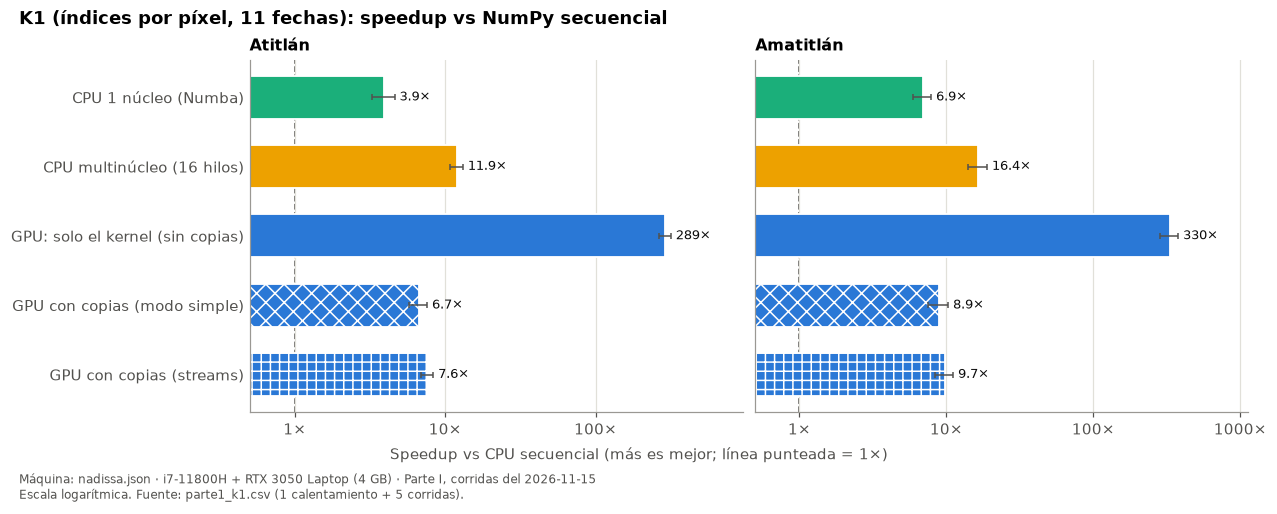

Guardado en resultados/graficos/: fig_03_1_k1_speedup.png


In [16]:
# 3. Función para los gráficos de speedup de la Parte I (un panel por lago).
def figura_por_lago(datos, filas, titulo, nombre, log=True, nota=None,
                    xlabel='Speedup vs CPU secuencial (más es mejor; línea punteada = 1×)'):
    # filas: lista de (fase en los datos, etiqueta del eje, color, trama)
    fig, ejes = plt.subplots(1, 2, figsize=(11.5, 0.5 * len(filas) + 1.7), layout='constrained')
    for ax, lago in zip(ejes, ['Atitlán', 'Amatitlán']):
        sub = datos[datos['lago'] == lago].set_index('fase')
        barras_h(ax, [f[1] for f in filas],
                 [sub.loc[f[0], 'speedup_vs_secuencial'] for f in filas],
                 [COLOR[f[2]] for f in filas], [f[3] for f in filas],
                 errores=[sub.loc[f[0], 'speedup_desv'] for f in filas], log=log)
        ax.set_title(lago)
    ejes[1].tick_params(axis='y', labelleft=False)  # las etiquetas ya están en el panel izquierdo
    fig.supxlabel(xlabel, fontsize=10, color=TINTA_SECUNDARIA)  # una sola etiqueta para los dos paneles
    fig.suptitle(titulo, x=0.01, ha='left', fontweight='bold', fontsize=11.5)
    guardar_figura(fig, nombre, 'nadissa', nota)


# 3.1 K1
figura_por_lago(datos_k1, [
    (K1_1N, 'CPU 1 núcleo (Numba)', 'CPU 1 núcleo', ''),
    (K1_MULTI, 'CPU multinúcleo (16 hilos)', 'CPU multinúcleo', ''),
    (K1_KERNEL, 'GPU: solo el kernel (sin copias)', 'GPU', ''),
    (K1_SIMPLE, 'GPU con copias (modo simple)', 'GPU', TRAMA_CON_COPIAS),
    (K1_STREAMS, 'GPU con copias (streams)', 'GPU', TRAMA_STREAMS),
], 'K1 (índices por píxel, 11 fechas): speedup vs NumPy secuencial', '03_1_k1_speedup',
    nota='Escala logarítmica. Fuente: parte1_k1.csv (1 calentamiento + 5 corridas).')

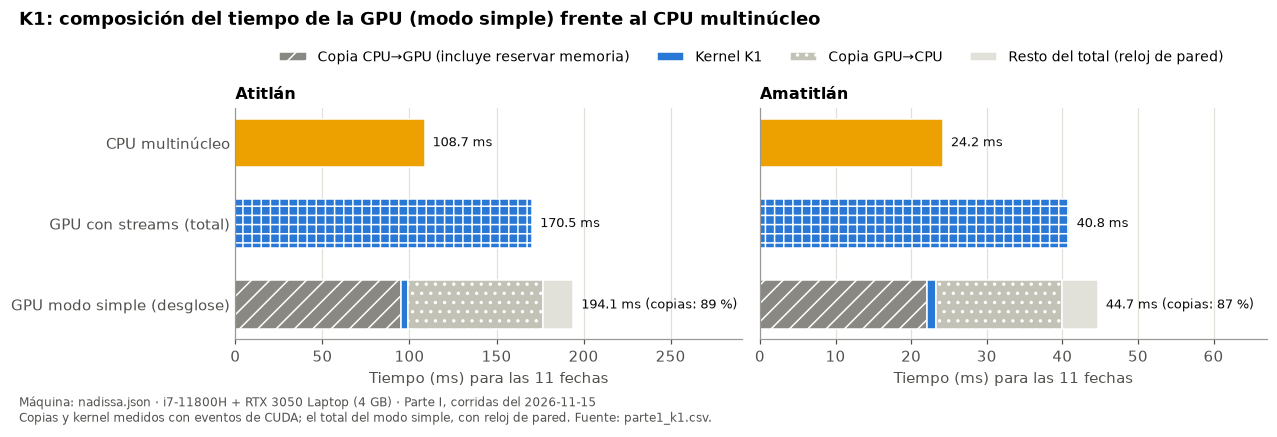

Guardado en resultados/graficos/: fig_03_2_k1_composicion_gpu.png


In [17]:
# 3.2 K1 en la GPU: composición del tiempo (copias y kernel) frente al CPU multinúcleo
segmentos = [(K1_IDA, 'Copia CPU→GPU (incluye reservar memoria)', GRIS_OSCURO, '//'),
             (K1_KERNEL, 'Kernel K1', COLOR['GPU'], ''),
             (K1_VUELTA, 'Copia GPU→CPU', GRIS_MEDIO, '..')]
fig, eje_leyenda, ejes = figura_con_leyenda(2, 11.5, 3.0)
for ax, lago in zip(ejes, ['Atitlán', 'Amatitlán']):
    ms = datos_k1[datos_k1['lago'] == lago].set_index('fase')['promedio_s'] * 1000
    ax.barh(2, ms[K1_MULTI], height=0.6, color=COLOR['CPU multinúcleo'], edgecolor='white', linewidth=1)
    ax.barh(1, ms[K1_STREAMS], height=0.6, color=COLOR['GPU'], hatch=TRAMA_STREAMS, edgecolor='white', linewidth=1)
    izquierda = 0.0
    for fase, _nombre, color, trama in segmentos:
        ax.barh(0, ms[fase], left=izquierda, height=0.6, color=color, hatch=trama, edgecolor='white', linewidth=1)
        izquierda += ms[fase]
    resto = max(ms[K1_SIMPLE] - izquierda, 0.0)  # parte del reloj de pared que no es copia ni kernel
    ax.barh(0, resto, left=izquierda, height=0.6, color=GRIS_CLARO, edgecolor='white', linewidth=1)
    pct = 100 * (ms[K1_IDA] + ms[K1_VUELTA]) / ms[K1_SIMPLE]
    for yi, total, extra in [(2, ms[K1_MULTI], ''), (1, ms[K1_STREAMS], ''), (0, ms[K1_SIMPLE], f' (copias: {pct:.0f} %)')]:
        ax.text(total, yi, f'  {total:.1f} ms' + extra, va='center', ha='left', fontsize=8.5, color=TINTA)
    ax.set_yticks([2, 1, 0], ['CPU multinúcleo', 'GPU con streams (total)', 'GPU modo simple (desglose)'])
    ax.set_xlim(0, ms[K1_SIMPLE] * 1.5)
    ax.set_xlabel('Tiempo (ms) para las 11 fechas')
    ax.set_title(lago)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
ejes[1].tick_params(axis='y', labelleft=False)
leyenda = [Patch(facecolor=c, hatch=t, edgecolor='white', label=n) for _f, n, c, t in segmentos]
leyenda.append(Patch(facecolor=GRIS_CLARO, edgecolor='white', label='Resto del total (reloj de pared)'))
eje_leyenda.legend(handles=leyenda, loc='center', ncol=4)
fig.suptitle('K1: composición del tiempo de la GPU (modo simple) frente al CPU multinúcleo', x=0.01, ha='left',
             fontweight='bold', fontsize=11.5)
guardar_figura(fig, '03_2_k1_composicion_gpu', 'nadissa',
               'Copias y kernel medidos con eventos de CUDA; el total del modo simple, con reloj de pared. Fuente: parte1_k1.csv.')

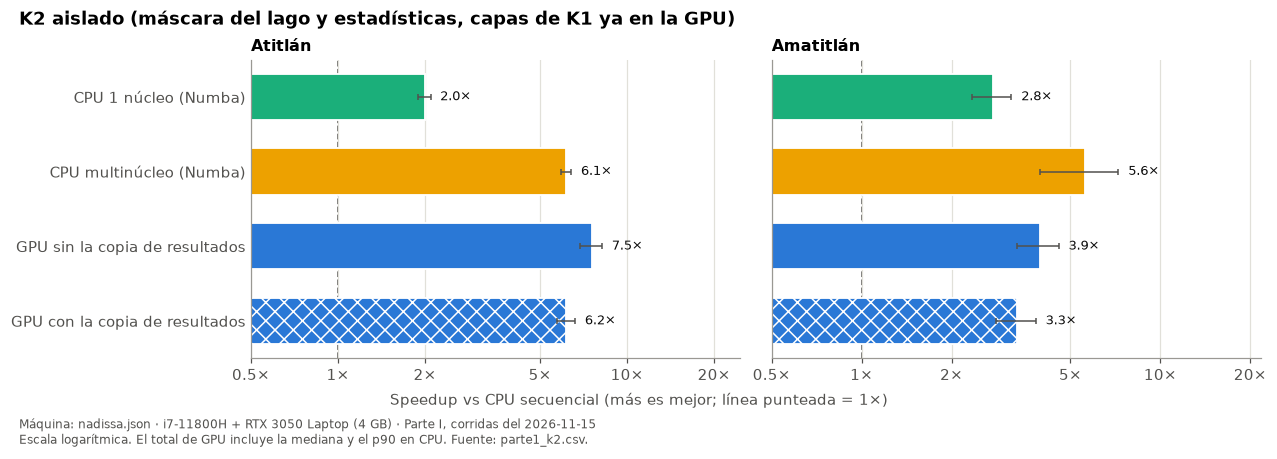

Guardado en resultados/graficos/: fig_03_3_k2_speedup.png


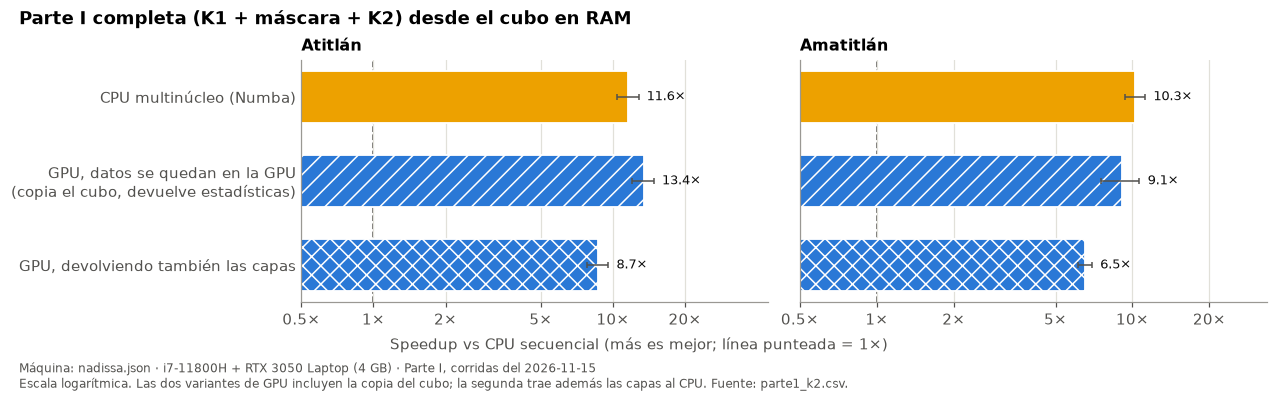

Guardado en resultados/graficos/: fig_03_4_parte1_completa_speedup.png


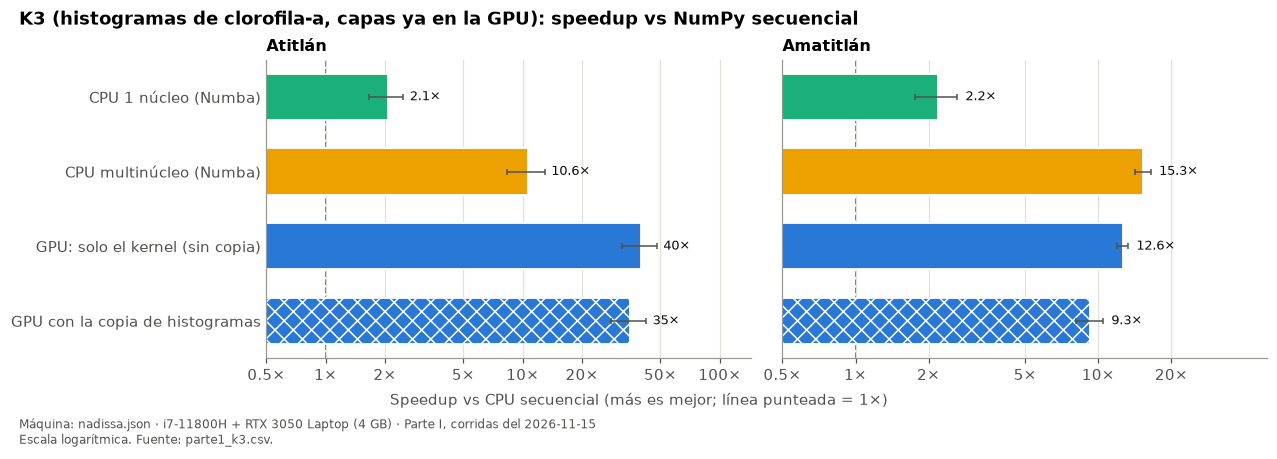

Guardado en resultados/graficos/: fig_03_5_k3_speedup.png


In [18]:
# 3.3 K2 aislado, 3.4 Parte I completa y 3.5 K3
figura_por_lago(datos_k2, [
    (K2_1N, 'CPU 1 núcleo (Numba)', 'CPU 1 núcleo', ''),
    (K2_MULTI, 'CPU multinúcleo (Numba)', 'CPU multinúcleo', ''),
    (K2_GPU_SIN, 'GPU sin la copia de resultados', 'GPU', ''),
    (K2_GPU, 'GPU con la copia de resultados', 'GPU', TRAMA_CON_COPIAS),
], 'K2 aislado (máscara del lago y estadísticas, capas de K1 ya en la GPU)', '03_3_k2_speedup',
    nota='Escala logarítmica. El total de GPU incluye la mediana y el p90 en CPU. Fuente: parte1_k2.csv.')

figura_por_lago(datos_p1, [
    (P1_MULTI, 'CPU multinúcleo (Numba)', 'CPU multinúcleo', ''),
    (P1_DATOS, 'GPU, datos se quedan en la GPU' + NL + '(copia el cubo, devuelve estadísticas)', 'GPU', '//'),
    (P1_CAPAS, 'GPU, devolviendo también las capas', 'GPU', TRAMA_CON_COPIAS),
], 'Parte I completa (K1 + máscara + K2) desde el cubo en RAM', '03_4_parte1_completa_speedup',
    nota='Escala logarítmica. Las dos variantes de GPU incluyen la copia del cubo; la segunda trae además las capas al CPU. Fuente: parte1_k2.csv.')

figura_por_lago(datos_k3, [
    (K3_1N, 'CPU 1 núcleo (Numba)', 'CPU 1 núcleo', ''),
    (K3_MULTI, 'CPU multinúcleo (Numba)', 'CPU multinúcleo', ''),
    (K3_KERNEL, 'GPU: solo el kernel (sin copia)', 'GPU', ''),
    (K3_GPU, 'GPU con la copia de histogramas', 'GPU', TRAMA_CON_COPIAS),
], 'K3 (histogramas de clorofila-a, capas ya en la GPU): speedup vs NumPy secuencial', '03_5_k3_speedup',
    nota='Escala logarítmica. Fuente: parte1_k3.csv.')

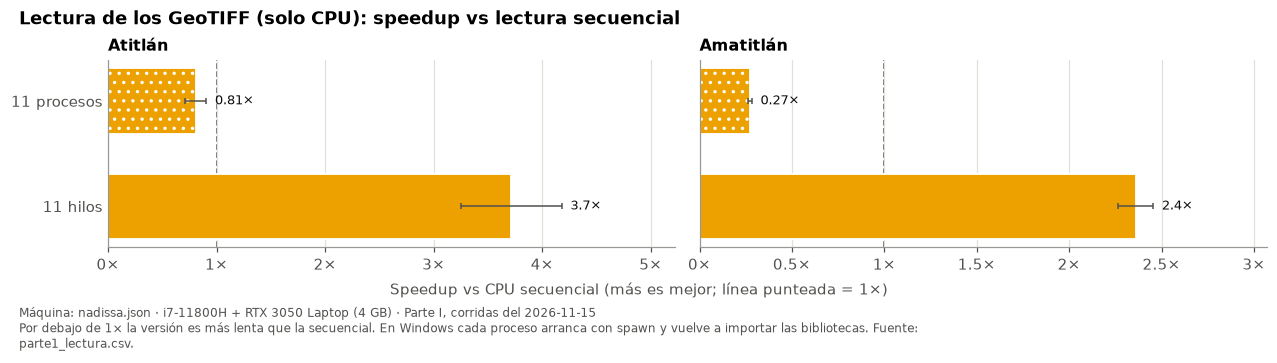

Guardado en resultados/graficos/: fig_03_6_lectura_speedup.png


In [19]:
# 3.6 Lectura del cubo (solo CPU)
figura_por_lago(datos_lectura, [
    (L_PROCESOS, '11 procesos', 'CPU multinúcleo', '..'),
    (L_HILOS, '11 hilos', 'CPU multinúcleo', ''),
], 'Lectura de los GeoTIFF (solo CPU): speedup vs lectura secuencial', '03_6_lectura_speedup', log=False,
    nota='Por debajo de 1× la versión es más lenta que la secuencial. En Windows cada proceso arranca con spawn y vuelve a importar las bibliotecas. Fuente: parte1_lectura.csv.')

## 4. Speedup por fase, Parte II

Color = versión de CPU contra la que se compara la GPU (naranja: secuencial; amarillo: multinúcleo). Trama cruzada = con copias CPU↔GPU.

**Sin copias** resta las copias medidas aparte (aproximación): entrenamiento − copia de X,y; predicción − (copia de X de prueba + copia del resultado). En el protocolo completo las copias no se separaron fase por fase: se resta una **cota** (todas las copias de cada ajuste). Como esa resta es la máxima posible, el tiempo de GPU sin copias es **≥** la cota y el speedup sin copias es **≤** el valor calculado (y ≥ el speedup con copias). Donde las copias no se pueden separar (la búsqueda y la predicción controlada de XGBoost con 120 538 filas) aparece «—».

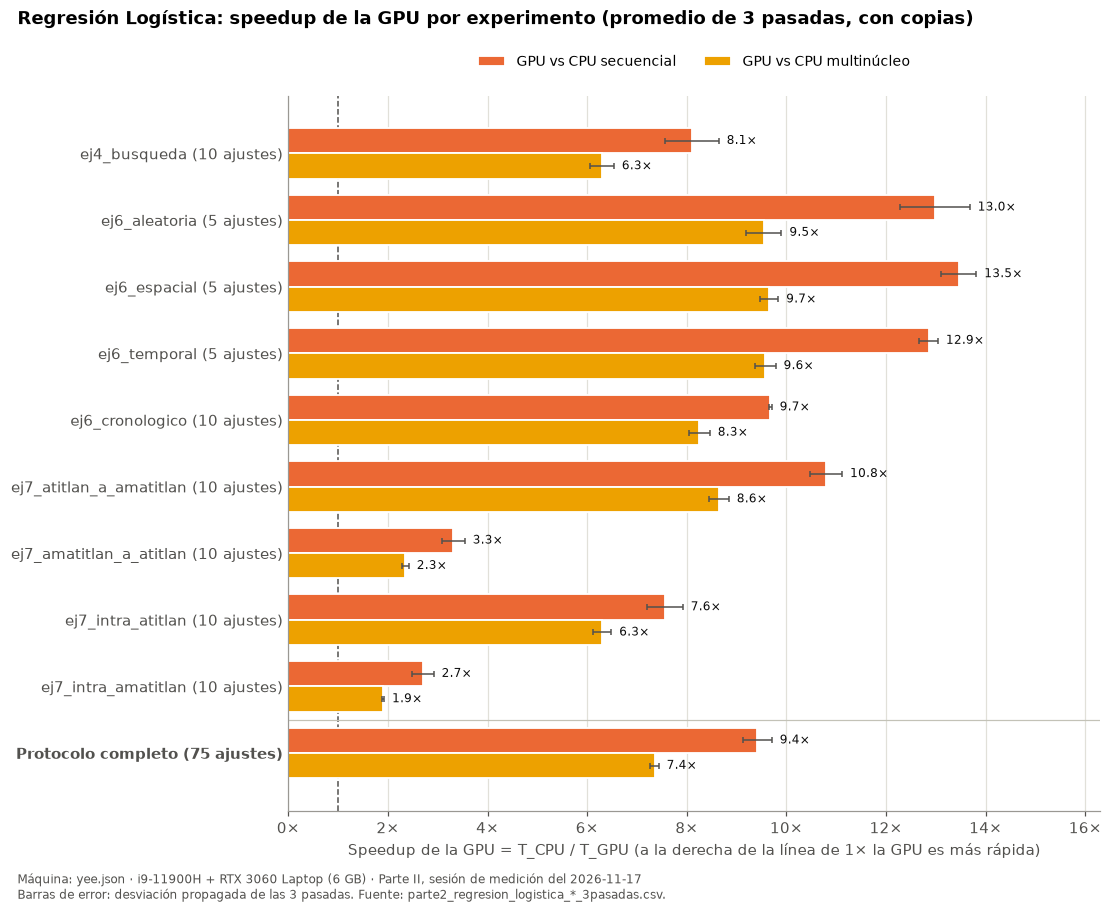

Guardado en resultados/graficos/: fig_04_1_speedup_experimentos_regresion_logistica.png


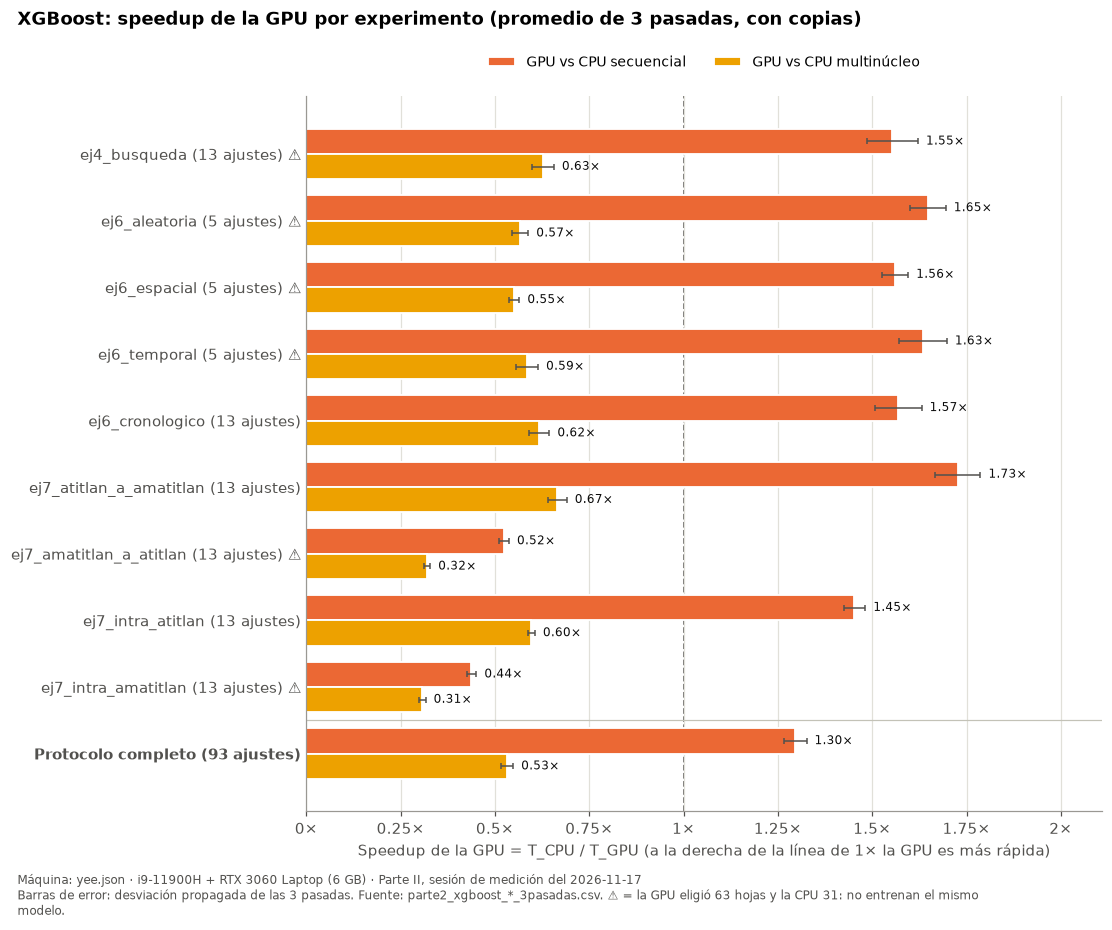

Guardado en resultados/graficos/: fig_04_1_speedup_experimentos_xgboost.png


In [20]:
# 4.1 Speedup de la GPU por experimento (promedio de 3 pasadas)
def figura_experimentos(modelo):
    datos = protocolo[modelo]
    dec = DEC_BAJO[modelo]
    etiquetas = []
    for _, f in datos.iterrows():
        aviso = ' ⚠' if f['mismo_modelo'] == False else ''  # noqa: E712 (None o bool)
        etiquetas.append(str(f['experimento']) + ' (' + str(f['ajustes']) + ' ajustes)' + aviso)
    n = len(datos)
    y = np.arange(n)[::-1].astype(float)
    alto = 0.38
    fig, eje_leyenda, (ax,) = figura_con_leyenda(1, 10, 0.55 * n + 1.8)
    extremo_max = 1.0
    for columna, ref, desplazamiento in [('speedup_vs_secuencial', 'CPU secuencial', alto / 2),
                                         ('speedup_vs_multinucleo', 'CPU multinúcleo', -alto / 2)]:
        valores = datos[columna].to_numpy(dtype=float)
        errores = np.nan_to_num(datos[columna + '_desv'].to_numpy(dtype=float))
        ax.barh(y + desplazamiento, valores, height=alto, color=COLOR[ref], edgecolor='white', linewidth=1.2,
                xerr=errores, error_kw=dict(ecolor=TINTA_SECUNDARIA, elinewidth=1, capsize=2), label='GPU vs ' + ref)
        extremo_max = max(extremo_max, np.nanmax(valores + errores))
        for yi, v, e in zip(y + desplazamiento, valores, errores):
            ax.text(v + e, yi, '  ' + fmt_x(v, dec), va='center', ha='left', fontsize=8, color=TINTA)
    ax.axvline(1, color=TINTA_SECUNDARIA, linewidth=1, linestyle='--', zorder=0)
    ax.axhline(0.5, color=GRIS_MEDIO, linewidth=0.8)  # separa el protocolo completo (abajo) de los experimentos
    ax.set_yticks(y, etiquetas)
    for texto in ax.get_yticklabels():
        if texto.get_text().startswith('Protocolo completo'):
            texto.set_fontweight('bold')
    ax.set_xlim(0, extremo_max * 1.18)
    formato_eje_speedup(ax, 'x', log=False)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
    ax.set_xlabel('Speedup de la GPU = T_CPU / T_GPU (a la derecha de la línea de 1× la GPU es más rápida)')
    eje_leyenda.legend(*ax.get_legend_handles_labels(), loc='center', ncol=2)
    fig.suptitle(MODELOS[modelo] + ': speedup de la GPU por experimento (promedio de 3 pasadas, con copias)',
                 x=0.01, ha='left', fontweight='bold', fontsize=11.5)
    nota = 'Barras de error: desviación propagada de las 3 pasadas. Fuente: parte2_' + modelo + '_*_3pasadas.csv.'
    if modelo == 'xgboost':
        nota += ' ⚠ = la GPU eligió 63 hojas y la CPU 31: no entrenan el mismo modelo.'
    guardar_figura(fig, '04_1_speedup_experimentos_' + modelo, 'yee', nota)


for modelo in MODELOS:
    figura_experimentos(modelo)

In [21]:
# 4.2 Tabla de speedup por fase con y sin copias
def fila_fase(modelo, clave, etiqueta, tiempos, gpu_sin, cota=False, aviso=False, fuente=''):
    ts, tm, tg = tiempos['CPU secuencial'][0], tiempos['CPU multinúcleo'][0], tiempos['GPU'][0]
    hay_sin = bool(np.isfinite(gpu_sin))
    return {'modelo': MODELOS[modelo], 'clave': modelo + ':' + clave, 'fase': etiqueta + (' ⚠' if aviso else ''),
            'cpu_secuencial_s': ts, 'cpu_multinucleo_s': tm, 'gpu_con_copias_s': tg, 'gpu_sin_copias_s': gpu_sin,
            'sin_copias_es_cota': cota,
            'S_con_vs_secuencial': ts / tg, 'S_con_vs_multinucleo': tm / tg,
            'S_sin_vs_secuencial': ts / gpu_sin if hay_sin else np.nan,
            'S_sin_vs_multinucleo': tm / gpu_sin if hay_sin else np.nan, 'fuente': fuente}


def tiempos_de(datos, indice):
    f = datos.loc[indice]
    return {'CPU secuencial': (f['cpu_secuencial_s'], f['cpu_secuencial_desv']),
            'CPU multinúcleo': (f['cpu_multinucleo_s'], f['cpu_multinucleo_desv']),
            'GPU': (f['gpu_s'], f['gpu_desv'])}


def tiempos_diag(d, paso):
    return {v: tiempo_diag(d, paso, v) for v in VARIANTES.values()}


filas_fases = []
for modelo in MODELOS:
    proto = protocolo[modelo].set_index('experimento')
    rep = representativos[modelo]
    prob = COPIA['prob_rl'] if modelo == 'regresion_logistica' else COPIA['prob_xgb']
    if modelo == 'regresion_logistica':
        copias_por_ajuste = COPIA['xy'] + COPIA['x_prueba'] + prob
    else:  # XGBoost: copias del diagnóstico (≈ 5.7 ms por ajuste)
        copias_por_ajuste = sum(tiempo_diag(diag, p, 'GPU')[0] for p in ['copia X,y a GPU', 'copia X prueba a GPU', 'copia resultado a CPU'])
    ajustes = int(proto.loc['Protocolo completo', 'ajustes'])
    t = tiempos_de(proto, 'Protocolo completo')
    filas_fases.append(fila_fase(modelo, 'protocolo', f'Protocolo completo ({ajustes} ajustes), 3 pasadas', t,
                                 t['GPU'][0] - ajustes * copias_por_ajuste, cota=True, aviso=(modelo == 'xgboost'),
                                 fuente='*_3pasadas.csv; sin copias = cota'))
    t = tiempos_de(rep, 'busqueda')
    filas_fases.append(fila_fase(modelo, 'busqueda', rep.loc['busqueda', 'fase'], t, np.nan, fuente='representativo'))
    t = tiempos_de(rep, 'entrenamiento')
    filas_fases.append(fila_fase(modelo, 'entrenamiento', rep.loc['entrenamiento', 'fase'], t, t['GPU'][0] - COPIA['xy'],
                                 fuente='representativo - copia X,y (parte2_copias_gpu.csv)'))
    t = tiempos_de(rep, 'prediccion')
    filas_fases.append(fila_fase(modelo, 'prediccion', rep.loc['prediccion', 'fase'], t, t['GPU'][0] - COPIA['x_prueba'] - prob,
                                 fuente='representativo - copias (parte2_copias_gpu.csv)'))

# XGBoost con los mismos hiperparámetros y con 3.75 M filas replicadas
for d, sufijo, texto_ajuste, texto_pred in [
        (diag, '281255', 'Ajuste con los mismos hiperparámetros, 281 255 filas', 'Predicción con el mismo modelo, 120 538 filas'),
        (escala, '3750000', 'Ajuste con 3 750 000 filas (replicadas)', 'Predicción de 1 607 145 filas (replicadas)')]:
    t = tiempos_diag(d, 'ruta real ajustar()')
    filas_fases.append(fila_fase('xgboost', 'ajuste_' + sufijo, texto_ajuste, t,
                                 t['GPU'][0] - tiempo_diag(d, 'copia X,y a GPU', 'GPU')[0], fuente='diagnóstico'))
    t = tiempos_diag(d, 'ruta real probabilidad()')
    # 'Sin copias' solo con 3.75 M filas. Con 120 538 filas no se calcula: la ruta real
    # (≈ 2.1 ms) tarda menos que la suma del desglose (≈ 8 ms), así que restarle las copias del desglose no tiene sentido.
    sin = np.nan
    if sufijo == '3750000':
        sin = t['GPU'][0] - tiempo_diag(d, 'copia X prueba a GPU', 'GPU')[0] - tiempo_diag(d, 'copia resultado a CPU', 'GPU')[0]
    filas_fases.append(fila_fase('xgboost', 'prediccion_' + sufijo, texto_pred, t, sin, fuente='diagnóstico'))

datos_fases = pd.DataFrame(filas_fases)
DEC_POR_NOMBRE = {MODELOS[m]: DEC_BAJO[m] for m in MODELOS}


def texto_par(a, b, dec, prefijo=''):
    if not np.isfinite(a):
        return '—'
    return prefijo + fmt_x(a, dec) + ' / ' + prefijo + fmt_x(b, dec)


tabla_fases = pd.DataFrame({
    'Modelo': datos_fases['modelo'],
    'Fase': datos_fases['fase'],
    'CPU sec. (s)': [fmt_tiempo_p2(v) for v in datos_fases['cpu_secuencial_s']],
    'CPU multi. (s)': [fmt_tiempo_p2(v) for v in datos_fases['cpu_multinucleo_s']],
    'GPU con copias (s)': [fmt_tiempo_p2(v) for v in datos_fases['gpu_con_copias_s']],
    'S con copias (vs sec. / vs multi.)': [texto_par(a, b, DEC_POR_NOMBRE[m]) for a, b, m in
                                           zip(datos_fases['S_con_vs_secuencial'], datos_fases['S_con_vs_multinucleo'], datos_fases['modelo'])],
    'GPU sin copias (s)': [('≥ ' if c else '≈ ') + fmt_tiempo_p2(v) if np.isfinite(v) else '—'
                           for v, c in zip(datos_fases['gpu_sin_copias_s'], datos_fases['sin_copias_es_cota'])],
    'S sin copias (vs sec. / vs multi.)': [texto_par(a, b, DEC_POR_NOMBRE[m], '≤ ' if c else '≈ ') for a, b, m, c in
                                           zip(datos_fases['S_sin_vs_secuencial'], datos_fases['S_sin_vs_multinucleo'],
                                               datos_fases['modelo'], datos_fases['sin_copias_es_cota'])],
})
guardar_tabla(tabla_fases, '04_2_speedup_por_fase_con_y_sin_copias', 'yee', datos_fases)

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Modelo,Fase,CPU sec. (s),CPU multi. (s),GPU con copias (s),S con copias (vs sec. / vs multi.),GPU sin copias (s),S sin copias (vs sec. / vs multi.)
0,Regresión Logística,"Protocolo completo (75 ajustes), 3 pasadas",29.52,23.06,3.14,9.4× / 7.4×,≥ 2.91,≤ 10.2× / ≤ 7.9×
1,Regresión Logística,Búsqueda ej4 (9 ajustes + predicción de validación),3.45,2.69,0.430,8.0× / 6.3×,—,—
2,Regresión Logística,Entrenamiento ej4 final (281 255 filas),0.535,0.519,0.0339,15.8× / 15.3×,≈ 0.0319,≈ 16.8× / ≈ 16.3×
3,Regresión Logística,Predicción ej4 prueba (120 538 filas),0.0150,0.0148,0.00126,11.9× / 11.8×,≈ 0.000216,≈ 70× / ≈ 69×
4,XGBoost,"Protocolo completo (93 ajustes), 3 pasadas ⚠",120.90,49.61,93.27,1.30× / 0.53×,≥ 92.74,≤ 1.30× / ≤ 0.53×
5,XGBoost,Búsqueda ej4 (12 ajustes + predicción de validación),17.78,7.07,11.08,1.60× / 0.64×,—,—
6,XGBoost,Entrenamiento ej4 final (281 255 filas) ⚠ 31 hojas CPU / 63 GPU,1.77,0.641,1.29,1.37× / 0.50×,≈ 1.29,≈ 1.38× / ≈ 0.50×
7,XGBoost,Predicción ej4 prueba (120 538 filas) ⚠ 31 hojas CPU / 63 GPU,0.161,0.0270,0.00281,57× / 9.61×,≈ 0.00186,≈ 86× / ≈ 14.5×
8,XGBoost,"Ajuste con los mismos hiperparámetros, 281 255 filas",1.80,0.754,0.632,2.85× / 1.19×,≈ 0.628,≈ 2.87× / ≈ 1.20×
9,XGBoost,"Predicción con el mismo modelo, 120 538 filas",0.141,0.0320,0.00213,66× / 15.0×,—,—


Guardado en resultados/graficos/: tabla_04_2_speedup_por_fase_con_y_sin_copias.csv, tabla_04_2_speedup_por_fase_con_y_sin_copias_datos.csv


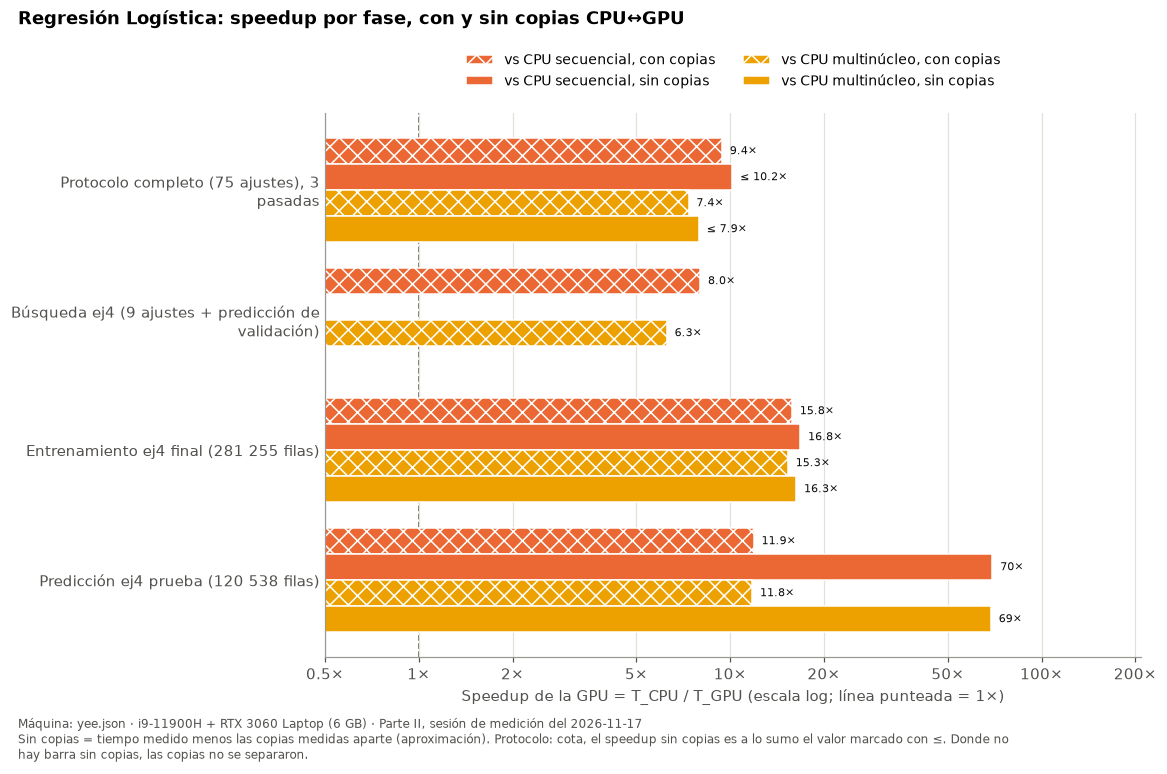

Guardado en resultados/graficos/: fig_04_3_speedup_fases_regresion_logistica.png


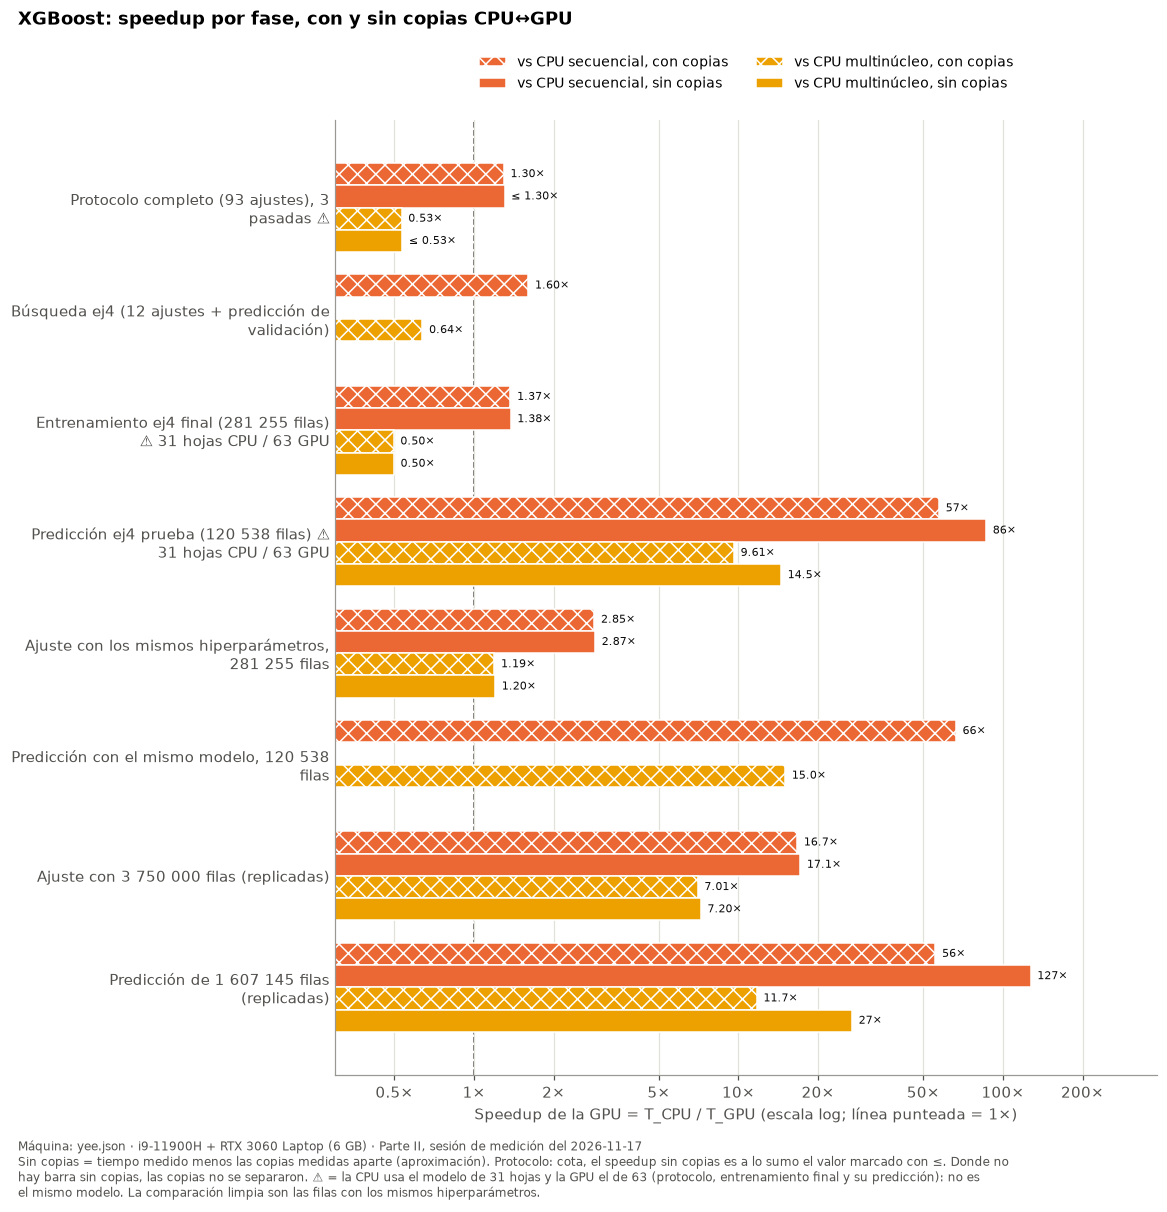

Guardado en resultados/graficos/: fig_04_3_speedup_fases_xgboost.png


In [22]:
# 4.3 Gráfico de speedup por fase con y sin copias, un gráfico por modelo
def figura_fases(modelo):
    datos = datos_fases[datos_fases['modelo'] == MODELOS[modelo]].reset_index(drop=True)
    dec = DEC_BAJO[modelo]
    n = len(datos)
    y = np.arange(n)[::-1].astype(float)
    alto = 0.2
    series = [
        ('S_con_vs_secuencial', 'CPU secuencial', TRAMA_CON_COPIAS, 1.5, 'vs CPU secuencial, con copias'),
        ('S_sin_vs_secuencial', 'CPU secuencial', '', 0.5, 'vs CPU secuencial, sin copias'),
        ('S_con_vs_multinucleo', 'CPU multinúcleo', TRAMA_CON_COPIAS, -0.5, 'vs CPU multinúcleo, con copias'),
        ('S_sin_vs_multinucleo', 'CPU multinúcleo', '', -1.5, 'vs CPU multinúcleo, sin copias'),
    ]
    fig, eje_leyenda, (ax,) = figura_con_leyenda(1, 10.5, 0.95 * n + 1.9, 0.7)
    todos = []
    cotas = datos['sin_copias_es_cota'].to_numpy(dtype=bool)
    for columna, ref, trama, posicion, etiqueta in series:
        valores = datos[columna].to_numpy(dtype=float)
        yy = y + posicion * alto
        hay = np.isfinite(valores)
        ax.barh(yy[hay], valores[hay], height=alto, color=COLOR[ref], hatch=trama, edgecolor='white', linewidth=1, label=etiqueta)
        todos.extend(valores[hay])
        for yi, v, cota in zip(yy[hay], valores[hay], cotas[hay]):
            prefijo = '≤ ' if (cota and columna.startswith('S_sin')) else ''
            ax.text(v * 1.06, yi, prefijo + fmt_x(v, dec), va='center', ha='left', fontsize=7.5, color=TINTA)
    formato_eje_speedup(ax, 'x', log=True)
    ax.set_xlim(min(0.5, min(todos) * 0.6), max(todos) * 3)
    ax.axvline(1, color=TINTA_SECUNDARIA, linewidth=1, linestyle='--', zorder=0)
    ax.set_yticks(y, [textwrap.fill(f, 40) for f in datos['fase']])
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
    ax.set_xlabel('Speedup de la GPU = T_CPU / T_GPU (escala log; línea punteada = 1×)')
    eje_leyenda.legend(*ax.get_legend_handles_labels(), loc='center', ncol=2)
    fig.suptitle(MODELOS[modelo] + ': speedup por fase, con y sin copias CPU↔GPU', x=0.01, ha='left',
                 fontweight='bold', fontsize=11.5)
    nota = 'Sin copias = tiempo medido menos las copias medidas aparte (aproximación). Protocolo: cota, el speedup sin copias es a lo sumo el valor marcado con ≤. Donde no hay barra sin copias, las copias no se separaron.'
    if modelo == 'xgboost':
        nota += (' ⚠ = la CPU usa el modelo de 31 hojas y la GPU el de 63 (protocolo, entrenamiento final y su predicción): '
                 'no es el mismo modelo. La comparación limpia son las filas con los mismos hiperparámetros.')
    guardar_figura(fig, '04_3_speedup_fases_' + modelo, 'yee', nota)


for modelo in MODELOS:
    figura_fases(modelo)

## 5. Escalabilidad de XGBoost (281 mil contra 3.75 M filas)

Mismo ajuste (lr 0.1, 31 hojas, 100 árboles) en las tres versiones. Las 3.75 M filas son **replicadas** a partir de ej4: solo sirven para medir tiempos (no dan un modelo válido) y son **solo dos puntos**.

In [23]:
# 5.1 Tabla de escalabilidad por fase y versión
N_FILAS = {'281 mil': 281255, '3.75 M': 3750000}
filas_txt, filas_num = [], []
for paso, etiqueta in PASOS_DIAG:
    for variante in ['GPU', 'CPU secuencial', 'CPU multinúcleo']:
        p1, s1 = tiempo_diag(diag, paso, variante)
        p2, s2 = tiempo_diag(escala, paso, variante)
        if not np.isfinite(p1):
            continue
        filas_num.append({'fase': etiqueta, 'version': variante, 't_281255_s': p1, 'desv_281255': s1,
                          't_3750000_s': p2, 'desv_3750000': s2, 'crecimiento': p2 / p1})
        filas_txt.append({'Fase': etiqueta, 'Versión': variante, '281 255 filas (s)': fmt_tiempo(p1, s1, 3),
                          '3 750 000 filas (s)': fmt_tiempo(p2, s2, 3), 'Crecimiento (13.3× más filas)': f'{p2 / p1:.1f}×'})
datos_escala = pd.DataFrame(filas_num)
guardar_tabla(pd.DataFrame(filas_txt), '05_1_escalabilidad_xgboost', 'yee', datos_escala)

# Costo fijo estimado con una recta por los dos puntos (suponiendo tiempo lineal en las filas)
g1 = tiempo_diag(diag, 'ruta real ajustar()', 'GPU')[0]
g2 = tiempo_diag(escala, 'ruta real ajustar()', 'GPU')[0]
pendiente = (g2 - g1) / (N_FILAS['3.75 M'] - N_FILAS['281 mil'])
costo_fijo = g1 - pendiente * N_FILAS['281 mil']
print(f'GPU: costo fijo ≈ {costo_fijo:.2f} s por ajuste + {pendiente * 1e6:.2f} µs por fila; '
      f'el costo fijo sería el {100 * costo_fijo / g1:.0f} % del ajuste de 281 mil filas (estimación de dos puntos).')

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Fase,Versión,281 255 filas (s),3 750 000 filas (s),Crecimiento (13.3× más filas)
0,"Copia X,y CPU→GPU",GPU,0.00400 ± 0.00192,0.0369 ± 0.0005,9.2×
1,Construir QuantileDMatrix,GPU,0.00968 ± 0.00049,0.0919 ± 0.0005,9.5×
2,Construir QuantileDMatrix,CPU secuencial,0.492 ± 0.008,5.22 ± 0.15,10.6×
3,Construir QuantileDMatrix,CPU multinúcleo,0.0938 ± 0.0024,1.21 ± 0.05,12.9×
4,Entrenamiento (100 árboles),GPU,0.652 ± 0.023,1.26 ± 0.01,1.9×
5,Entrenamiento (100 árboles),CPU secuencial,1.40 ± 0.09,16.9 ± 0.7,12.1×
6,Entrenamiento (100 árboles),CPU multinúcleo,0.556 ± 0.046,8.80 ± 0.38,15.8×
7,Copia X de prueba CPU→GPU,GPU,0.00142 ± 0.00008,0.0160 ± 0.0005,11.2×
8,Predicción,GPU,0.00640 ± 0.00401,0.0151 ± 0.0020,2.4×
9,Predicción,CPU secuencial,0.166 ± 0.002,1.98 ± 0.17,11.9×


Guardado en resultados/graficos/: tabla_05_1_escalabilidad_xgboost.csv, tabla_05_1_escalabilidad_xgboost_datos.csv
GPU: costo fijo ≈ 0.57 s por ajuste + 0.22 µs por fila; el costo fijo sería el 90 % del ajuste de 281 mil filas (estimación de dos puntos).


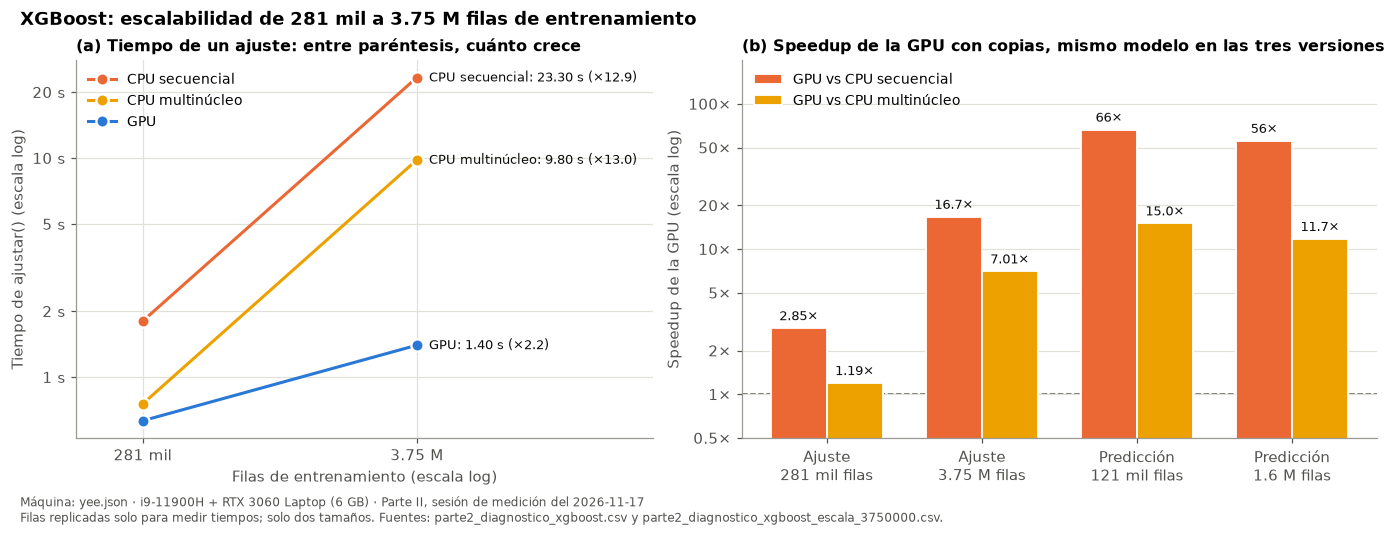

Guardado en resultados/graficos/: fig_05_escalabilidad_xgboost.png


In [24]:
# 5.2 Gráfico de escalabilidad: (a) tiempo de un ajuste según las filas; (b) speedup de la GPU con copias
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), layout='constrained', gridspec_kw={'width_ratios': [1, 1.1]})
x = list(N_FILAS.values())
for variante in ['CPU secuencial', 'CPU multinúcleo', 'GPU']:
    ys = [tiempo_diag(diag, 'ruta real ajustar()', variante)[0], tiempo_diag(escala, 'ruta real ajustar()', variante)[0]]
    ax1.plot(x, ys, marker='o', markersize=8, linewidth=2, color=COLOR[variante], markeredgecolor='white',
             markeredgewidth=1.5, label=variante)
    ax1.annotate(f'{variante}: {ys[1]:.2f} s (×{ys[1] / ys[0]:.1f})', xy=(x[1], ys[1]), xytext=(8, 0),
                 textcoords='offset points', va='center', fontsize=8.5, color=TINTA)
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xticks(x, list(N_FILAS.keys()))
ax1.xaxis.set_minor_locator(NullLocator())
ax1.set_xlim(1.5e5, 3.5e7)
ax1.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
ax1.yaxis.set_minor_locator(NullLocator())
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _pos: f'{v:g} s'))
ax1.set_xlabel('Filas de entrenamiento (escala log)')
ax1.set_ylabel('Tiempo de ajustar() (escala log)')
ax1.set_title('(a) Tiempo de un ajuste: entre paréntesis, cuánto crece')
ax1.legend(loc='upper left')

grupos = [('Ajuste' + NL + '281 mil filas', 'xgboost:ajuste_281255'), ('Ajuste' + NL + '3.75 M filas', 'xgboost:ajuste_3750000'),
          ('Predicción' + NL + '121 mil filas', 'xgboost:prediccion_281255'), ('Predicción' + NL + '1.6 M filas', 'xgboost:prediccion_3750000')]
por_clave = datos_fases.set_index('clave')
xf = np.arange(len(grupos))
ancho = 0.36
maximo = 1.0
for k, (columna, ref) in enumerate([('S_con_vs_secuencial', 'CPU secuencial'), ('S_con_vs_multinucleo', 'CPU multinúcleo')]):
    vals = [por_clave.loc[c, columna] for _, c in grupos]
    pos = xf + (k - 0.5) * ancho
    ax2.bar(pos, vals, width=ancho, color=COLOR[ref], edgecolor='white', linewidth=1.2, label='GPU vs ' + ref)
    maximo = max(maximo, max(vals))
    for xb, v in zip(pos, vals):
        ax2.text(xb, v * 1.08, fmt_x(v, 2), ha='center', va='bottom', fontsize=8.5, color=TINTA)
formato_eje_speedup(ax2, 'y', log=True)
ax2.set_ylim(0.5, maximo * 3)
ax2.axhline(1, color=TINTA_SECUNDARIA, linewidth=1, linestyle='--', zorder=0)
ax2.set_xticks(xf, [g for g, _ in grupos])
ax2.grid(axis='x', visible=False)
ax2.set_ylabel('Speedup de la GPU (escala log)')
ax2.set_title('(b) Speedup de la GPU con copias, mismo modelo en las tres versiones')
ax2.legend(loc='upper left')
fig.suptitle('XGBoost: escalabilidad de 281 mil a 3.75 M filas de entrenamiento', x=0.01, ha='left',
             fontweight='bold', fontsize=11.5)
guardar_figura(fig, '05_escalabilidad_xgboost', 'yee',
               'Filas replicadas solo para medir tiempos; solo dos tamaños. Fuentes: parte2_diagnostico_xgboost.csv y parte2_diagnostico_xgboost_escala_3750000.csv.')

## 6. Utilización de la GPU (nvidia-smi)

**Parte II:** pasada aparte de la medición de tiempos (muestrear nvidia-smi agrega carga), con una muestra cada 200 ms. `[Unknown Error]` se trata como dato faltante.

**Parte I:** el registro está incompleto (archivos vacíos o cortados a 4096 bytes). Solo se grafica la memoria usada de K1 y K2 en Atitlán y **no se presenta como prueba de utilización**.

In [25]:
# 6.1 Lectura de los CSV de nvidia-smi y resumen de la Parte II
COLUMNAS_SMI = {'utilization.gpu [%]': 'util_gpu', 'utilization.memory [%]': 'util_memoria',
                'memory.used [MiB]': 'memoria_mib', 'temperature.gpu': 'temperatura_c', 'power.draw [W]': 'potencia_w'}
FORMATO_HORA = '%Y/%m/%d %H:%M:%S.%f'


def leer_nvidia_smi(ruta):
    # Devuelve (muestras con hora válida, filas del CSV). Un archivo vacío devuelve (None, 0).
    if ruta.stat().st_size == 0:
        return None, 0
    d = pd.read_csv(ruta, skipinitialspace=True)
    d.columns = [c.strip() for c in d.columns]
    filas_csv = len(d)
    d['tiempo'] = pd.to_datetime(d['timestamp'], format=FORMATO_HORA, errors='coerce')
    d = d.dropna(subset=['tiempo']).copy()  # descarta una última línea cortada
    for original, nuevo in COLUMNAS_SMI.items():
        texto = d[original].astype(str)
        for unidad in ('%', 'MiB', 'W'):
            texto = texto.str.replace(unidad, '', regex=False)
        d[nuevo] = pd.to_numeric(texto.str.strip(), errors='coerce')  # '[Unknown Error]' -> NaN
    d['segundos'] = (d['tiempo'] - d['tiempo'].iloc[0]).dt.total_seconds()
    return d, filas_csv


SMI, resumen_smi = {}, {}
for modelo in MODELOS:
    d, filas_csv = leer_nvidia_smi(NVIDIA_SMI / f'parte2_{modelo}_gpu.csv')
    fases = pd.read_csv(NVIDIA_SMI / f'parte2_{modelo}_gpu_fases.csv')
    for columna in ('inicio', 'fin'):
        fases[columna] = (pd.to_datetime(fases[columna], format=FORMATO_HORA) - d['tiempo'].iloc[0]).dt.total_seconds()
    fases['duracion_s'] = fases['fin'] - fases['inicio']
    vueltas = fases[fases['fase'].str.startswith('vuelta')]
    SMI[modelo] = (d, fases)
    resumen_smi[modelo] = {
        'filas_csv': filas_csv, 'muestras': len(d), 'vueltas': len(vueltas),
        'vuelta_min_s': vueltas['duracion_s'].min(), 'vuelta_max_s': vueltas['duracion_s'].max(),
        'calentamiento_s': fases.loc[fases['fase'] == 'calentamiento', 'duracion_s'].iloc[0],
        'util_max': d['util_gpu'].max(), 'util_prom': d['util_gpu'].mean(),
        'umem_max': d['util_memoria'].max(), 'umem_prom': d['util_memoria'].mean(),
        'mem_max': d['memoria_mib'].max(), 'mem_prom': d['memoria_mib'].mean(),
        'pot_max': d['potencia_w'].max(), 'pot_prom': d['potencia_w'].mean(),
        'temp_max': d['temperatura_c'].max(), 'temp_prom': d['temperatura_c'].mean(),
    }


def par(r, clave, unidad, dec_max=0):
    return f"{r[clave + '_max']:.{dec_max}f} {unidad} / {r[clave + '_prom']:.1f} {unidad}"


filas = []
for modelo, r in resumen_smi.items():
    filas.append({
        'Modelo': MODELOS[modelo],
        'Filas del CSV / muestras con hora válida': f"{r['filas_csv']} / {r['muestras']}",
        'Vueltas del protocolo (duración)': f"{r['vueltas']} ({r['vuelta_min_s']:.1f}–{r['vuelta_max_s']:.1f} s); calentamiento {r['calentamiento_s']:.1f} s",
        'Utilización de GPU (máx. / prom.)': par(r, 'util', '%'),
        'Utilización de memoria (máx. / prom.)': par(r, 'umem', '%'),
        'Memoria usada (máx. / prom.)': par(r, 'mem', 'MiB'),
        'Potencia (máx. / prom.)': par(r, 'pot', 'W', 1),
        'Temperatura (máx. / prom.)': par(r, 'temp', '°C'),
    })
tabla_smi = pd.DataFrame(filas).set_index('Modelo').T.reset_index().rename(columns={'index': 'Medida'})
guardar_tabla(tabla_smi, '06_1_nvidia_smi_parte2', 'yee', pd.DataFrame(resumen_smi).T.reset_index(names='modelo'))

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

Modelo,Medida,Regresión Logística,XGBoost
0,Filas del CSV / muestras con hora válida,597 / 596,476 / 476
1,Vueltas del protocolo (duración),15 (8.0–8.7 s); calentamiento 2.5 s,1 (96.3–96.3 s); calentamiento 3.4 s
2,Utilización de GPU (máx. / prom.),65 % / 18.7 %,48 % / 38.2 %
3,Utilización de memoria (máx. / prom.),21 % / 5.6 %,8 % / 2.4 %
4,Memoria usada (máx. / prom.),243 MiB / 236.7 MiB,337 MiB / 280.5 MiB
5,Potencia (máx. / prom.),60.0 W / 43.9 W,53.2 W / 45.7 W
6,Temperatura (máx. / prom.),67 °C / 60.2 °C,65 °C / 60.2 °C


Guardado en resultados/graficos/: tabla_06_1_nvidia_smi_parte2.csv, tabla_06_1_nvidia_smi_parte2_datos.csv


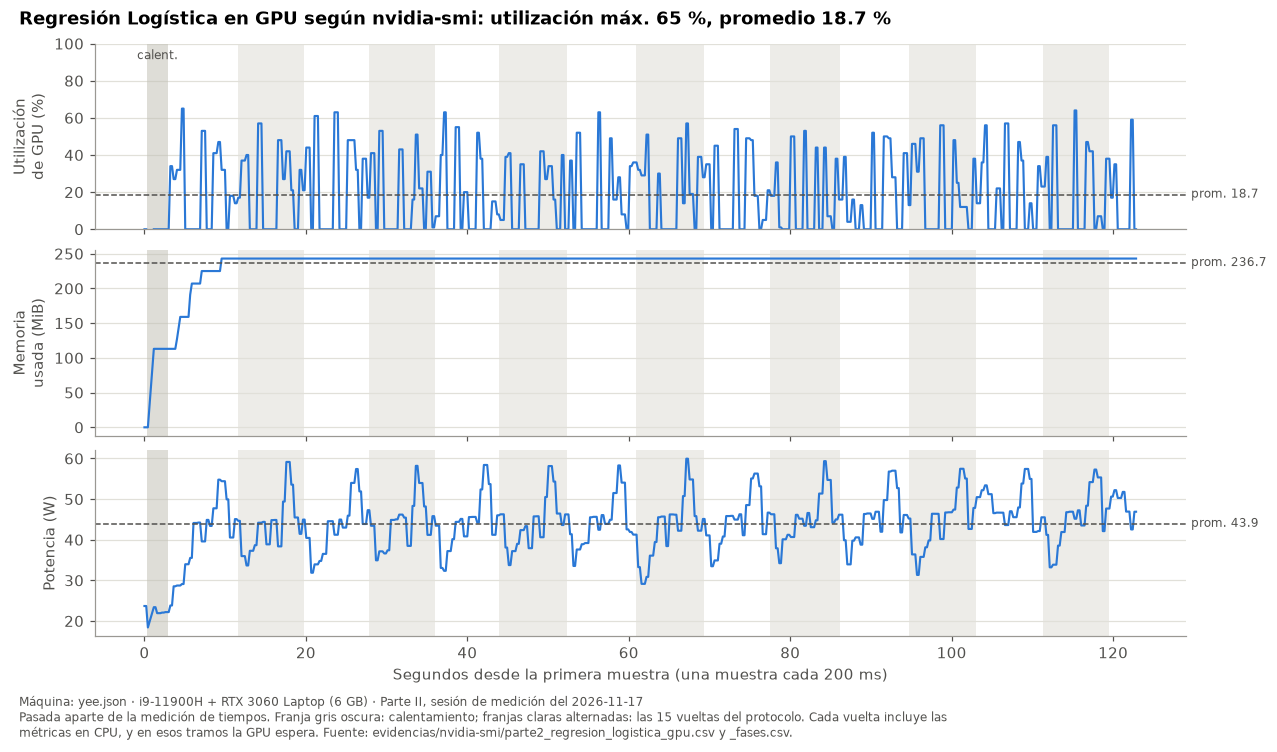

Guardado en resultados/graficos/: fig_06_2_nvidia_smi_regresion_logistica.png


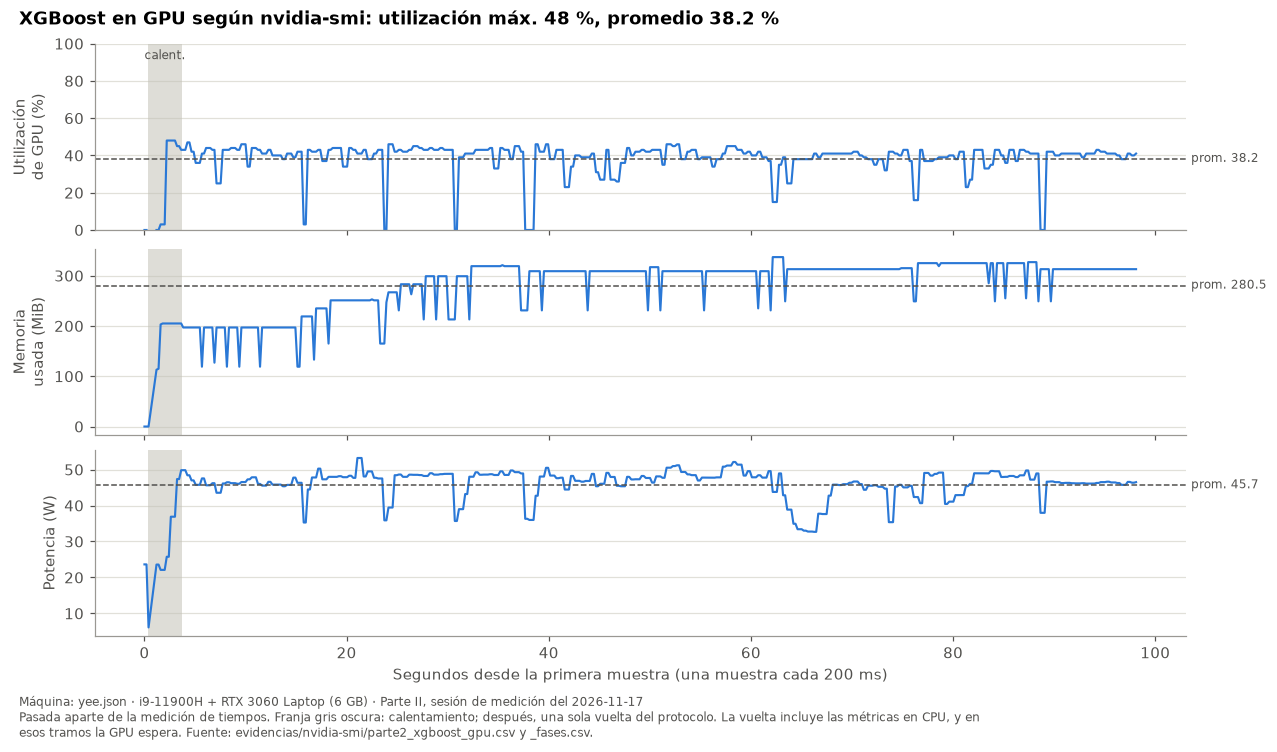

Guardado en resultados/graficos/: fig_06_2_nvidia_smi_xgboost.png


In [26]:
# 6.2 Series de tiempo de nvidia-smi, Parte II (un gráfico por modelo; paneles separados, sin doble eje)
def figura_smi(modelo):
    d, fases = SMI[modelo]
    paneles = [('util_gpu', 'Utilización' + NL + 'de GPU (%)', (0, 100)),
               ('memoria_mib', 'Memoria' + NL + 'usada (MiB)', None),
               ('potencia_w', 'Potencia (W)', None)]
    fig, ejes = plt.subplots(3, 1, figsize=(11.5, 6.2), sharex=True, layout='constrained')
    for ax, (columna, etiqueta, limites) in zip(ejes, paneles):
        for i, f in enumerate(fases.itertuples()):
            if f.fase == 'calentamiento':
                ax.axvspan(f.inicio, f.fin, color=GRIS_MEDIO, alpha=0.55, linewidth=0)
            elif i % 2 == 0:
                ax.axvspan(f.inicio, f.fin, color=GRIS_CLARO, alpha=0.6, linewidth=0)
        ax.plot(d['segundos'], d[columna], color=COLOR['GPU'], linewidth=1.4)
        media = d[columna].mean()
        ax.axhline(media, color=TINTA_SECUNDARIA, linewidth=1, linestyle='--')
        ax.text(1.005, media, f'prom. {media:.1f}', transform=ax.get_yaxis_transform(), va='center', ha='left',
                fontsize=8, color=TINTA_SECUNDARIA)
        ax.set_ylabel(etiqueta)
        if limites:
            ax.set_ylim(*limites)
        ax.grid(axis='x', visible=False)
    calentamiento = fases[fases['fase'] == 'calentamiento'].iloc[0]
    ejes[0].text((calentamiento['inicio'] + calentamiento['fin']) / 2, 97, 'calent.', ha='center', va='top',
                 fontsize=8, color=TINTA_SECUNDARIA)
    ejes[-1].set_xlabel('Segundos desde la primera muestra (una muestra cada 200 ms)')
    r = resumen_smi[modelo]
    fig.suptitle(f"{MODELOS[modelo]} en GPU según nvidia-smi: utilización máx. {r['util_max']:.0f} %, promedio {r['util_prom']:.1f} %",
                 x=0.01, ha='left', fontweight='bold', fontsize=11.5)
    n_vueltas = int(fases['fase'].str.startswith('vuelta').sum())
    if n_vueltas == 1:
        franjas = ('Franja gris oscura: calentamiento; después, una sola vuelta del protocolo. '
                   'La vuelta incluye las métricas en CPU, y en esos tramos la GPU espera. ')
    else:
        franjas = (f'Franja gris oscura: calentamiento; franjas claras alternadas: las {n_vueltas} vueltas del protocolo. '
                   'Cada vuelta incluye las métricas en CPU, y en esos tramos la GPU espera. ')
    nota = ('Pasada aparte de la medición de tiempos. ' + franjas +
            'Fuente: evidencias/nvidia-smi/parte2_' + modelo + '_gpu.csv y _fases.csv.')
    guardar_figura(fig, '06_2_nvidia_smi_' + modelo, 'yee', nota)


for modelo in MODELOS:
    figura_smi(modelo)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

,Archivo,Bytes,Muestras,Utilización GPU máx. (%),Memoria usada (MiB),Estado
0,parte1_k1_Amatitlan.csv,0,0,—,—,vacío: no se registró nada
1,parte1_k1_Atitlan.csv,4096,39,0,363–363,"probablemente truncado (mide exactamente 4096 bytes, un bloque de escritura)"
2,parte1_k2_Amatitlan.csv,0,0,—,—,vacío: no se registró nada
3,parte1_k2_Atitlan.csv,4096,39,1,359–1137,truncado a 4096 bytes (la última línea quedó incompleta)
4,parte1_k3_Amatitlan.csv,0,0,—,—,vacío: no se registró nada
5,parte1_k3_Atitlan.csv,0,0,—,—,vacío: no se registró nada


Guardado en resultados/graficos/: tabla_06_3_nvidia_smi_parte1_estado.csv


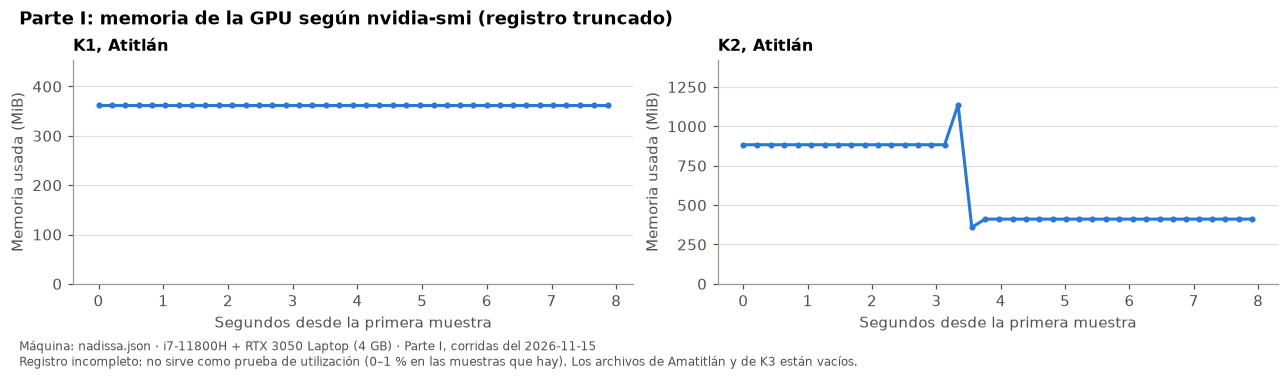

Guardado en resultados/graficos/: fig_06_3_nvidia_smi_parte1_memoria.png


In [27]:
# 6.3 nvidia-smi de la Parte I: estado de los archivos y memoria usada (registro incompleto)
filas, series_p1 = [], {}
for ruta in sorted(NVIDIA_SMI.glob('parte1_*.csv')):
    tamano = ruta.stat().st_size
    fila = {'Archivo': ruta.name, 'Bytes': tamano}
    if tamano == 0:
        fila.update({'Muestras': 0, 'Utilización GPU máx. (%)': '—', 'Memoria usada (MiB)': '—', 'Estado': 'vacío: no se registró nada'})
    else:
        d, _filas = leer_nvidia_smi(ruta)
        ultima = ruta.read_text(encoding='utf-8', errors='replace').rstrip().splitlines()[-1]
        incompleta = len(ultima.split(',')) < len(COLUMNAS_SMI) + 3 or not ultima.rstrip().endswith('W')
        if incompleta:
            estado = f'truncado a {tamano} bytes (la última línea quedó incompleta)'
        elif tamano == 4096:
            estado = 'probablemente truncado (mide exactamente 4096 bytes, un bloque de escritura)'
        else:
            estado = 'completo'
        fila.update({'Muestras': len(d), 'Utilización GPU máx. (%)': f"{d['util_gpu'].max():.0f}",
                     'Memoria usada (MiB)': f"{d['memoria_mib'].min():.0f}–{d['memoria_mib'].max():.0f}", 'Estado': estado})
        series_p1[ruta.stem] = d
    filas.append(fila)
guardar_tabla(pd.DataFrame(filas), '06_3_nvidia_smi_parte1_estado', 'nadissa')

if series_p1:
    fig, ejes = plt.subplots(1, len(series_p1), figsize=(5.8 * len(series_p1), 3.0), layout='constrained', squeeze=False)
    for ax, (nombre, d) in zip(ejes[0], series_p1.items()):
        ax.plot(d['segundos'], d['memoria_mib'], color=COLOR['GPU'], linewidth=2, marker='o', markersize=3)
        ax.set_ylim(0, d['memoria_mib'].max() * 1.25)
        ax.set_title(nombre.replace('parte1_', '').replace('_', ', ').upper().replace('ATITLAN', 'Atitlán'))
        ax.set_xlabel('Segundos desde la primera muestra')
        ax.set_ylabel('Memoria usada (MiB)')
        ax.grid(axis='x', visible=False)
    fig.suptitle('Parte I: memoria de la GPU según nvidia-smi (registro truncado)', x=0.01, ha='left',
                 fontweight='bold', fontsize=11.5)
    guardar_figura(fig, '06_3_nvidia_smi_parte1_memoria', 'nadissa',
                   'Registro incompleto: no sirve como prueba de utilización (0–1 % en las muestras que hay). Los archivos de Amatitlán y de K3 están vacíos.')

## 7. Validación CPU vs GPU

Parte I: cada versión contra `lab4` y la lectura contra `indices.leer_bandas`. Parte II: Regresión Logística (criterio A/B1/B2/B3 y métricas por experimento) y XGBoost (criterio B1, prueba con hiperparámetros idénticos y prueba extendida).

In [28]:
# 7.1 Parte I: K1, K2, K3 y lectura contra lab4
NOMBRE_CAPA = {'ndvi': 'NDVI', 'ndwi': 'NDWI', 'ndci': 'NDCI', 'fai': 'FAI', 'chla': 'Clorofila-a'}
k1v = pd.read_csv(VALIDACION / 'k1_vs_lab4.csv')
filas = []
for (lago, version), g in k1v.groupby(['lago', 'version'], sort=False):
    flot = g[g['tipo'] == 'float32'].set_index('capa')
    masc = g[g['tipo'] == 'mascara']
    fila = {'Lago': NOMBRE_LAGO.get(lago, lago), 'Versión': version}
    for capa, nombre in NOMBRE_CAPA.items():
        fila['Error máx. ' + nombre] = fmt_cientifico(flot.loc[capa, 'error_abs_max'])
    fila['NaN distintos'] = int(flot['nan_distintos'].sum())
    fila['Píxeles distintos en máscaras (agua, válidos, y_alta)'] = int(masc['pixeles_distintos'].sum())
    fila['Píxeles-fecha comparados'] = '{:,}'.format(int(g['pixeles_total'].iloc[0])).replace(',', ' ')
    filas.append(fila)
display(Markdown('**K1 contra lab4/indices.py** (k1_vs_lab4.csv)'))
guardar_tabla(pd.DataFrame(filas), '07_1_validacion_k1', 'nadissa')

k2v = pd.read_csv(VALIDACION / 'k2_vs_lab4.csv')
CONTEOS_K2 = ['pixeles_analizados', 'area_lago_km2', 'pct_alto', 'pct_fai_alto', 'cobertura_valida_pct', 'nubosidad_pct']
filas = []
for (lago, version), g in k2v.groupby(['lago', 'version'], sort=False):
    est = g[g['columna'] != 'mascara_lago']
    peor = est.loc[est['dif_rel_max'].idxmax()]
    filas.append({'Lago': NOMBRE_LAGO.get(lago, lago), 'Versión': version,
                  'Máscara del lago: píxeles distintos': int(g.loc[g['columna'] == 'mascara_lago', 'pixeles_distintos'].sum()),
                  'Conteos y porcentajes: dif. máx.': fmt_cientifico(est.loc[est['columna'].isin(CONTEOS_K2), 'dif_abs_max'].max()),
                  'Estadísticas: dif. relativa máx.': fmt_cientifico(peor['dif_rel_max']),
                  'Columna con esa diferencia': peor['columna']})
display(Markdown('**K2 contra procesar.resumen** (k2_vs_lab4.csv)'))
guardar_tabla(pd.DataFrame(filas), '07_2_validacion_k2', 'nadissa')

k3v = pd.read_csv(VALIDACION / 'k3_vs_lab4.csv')
tabla_k3v = pd.DataFrame({'Lago': k3v['lago'].map(NOMBRE_LAGO), 'Versión': k3v['version'],
                          'Bins con conteo distinto': k3v['conteos_distintos'], 'Dif. máx. de conteo': k3v['dif_abs_max'],
                          'Valores contados': k3v['total'], 'Valores contados (NumPy)': k3v['total_ref']})
display(Markdown('**K3 contra np.histogram** (k3_vs_lab4.csv)'))
guardar_tabla(tabla_k3v, '07_3_validacion_k3', 'nadissa')

lecv = pd.read_csv(VALIDACION / 'lectura_vs_lab4.csv')
tabla_lecv = pd.DataFrame({'Lago': lecv['lago'].map(NOMBRE_LAGO), 'Forma del cubo': lecv['forma_cubo'],
                           'MB': lecv['megabytes_cubo'], 'Bandas distintas': lecv['bandas_distintas'],
                           'Píxeles válidos distintos': lecv['pixeles_validos_distintos'],
                           'Procesos = secuencial': lecv['procesos_igual_a_secuencial'],
                           'Hilos = secuencial': lecv['hilos_igual_a_secuencial']})
display(Markdown('**Lectura contra indices.leer_bandas** (lectura_vs_lab4.csv)'))
guardar_tabla(tabla_lecv, '07_4_validacion_lectura', 'nadissa')

**K1 contra lab4/indices.py** (k1_vs_lab4.csv)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

,Lago,Versión,Error máx. NDVI,Error máx. NDWI,Error máx. NDCI,Error máx. FAI,Error máx. Clorofila-a,NaN distintos,"Píxeles distintos en máscaras (agua, válidos, y_alta)",Píxeles-fecha comparados
0,Atitlán,CPU 1 nucleo,0,0,0,6.0e-08,6.1e-05,0,0,13 297 680
1,Atitlán,CPU multinucleo,0,0,0,6.0e-08,6.1e-05,0,0,13 297 680
2,Atitlán,GPU simple,0,0,0,5.2e-08,6.1e-05,0,0,13 297 680
3,Atitlán,GPU streams,0,0,0,5.2e-08,6.1e-05,0,0,13 297 680
4,Amatitlán,CPU 1 nucleo,0,0,0,3.0e-08,6.1e-05,0,0,3 438 369
5,Amatitlán,CPU multinucleo,0,0,0,3.0e-08,6.1e-05,0,0,3 438 369
6,Amatitlán,GPU simple,0,0,0,6.0e-08,6.1e-05,0,0,3 438 369
7,Amatitlán,GPU streams,0,0,0,6.0e-08,6.1e-05,0,0,3 438 369


Guardado en resultados/graficos/: tabla_07_1_validacion_k1.csv


**K2 contra procesar.resumen** (k2_vs_lab4.csv)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

... (6 outputs left out)

**Lectura contra indices.leer_bandas** (lectura_vs_lab4.csv)

*Máquina: nadissa.json · i7-11800H + RTX 3050 Laptop (4 GB) · Parte I, corridas del 2026-11-15*

,Lago,Forma del cubo,MB,Bandas distintas,Píxeles válidos distintos,Procesos = secuencial,Hilos = secuencial
0,Atitlán,11x9x876x1380,478.7,0,0,True,True
1,Amatitlán,11x9x459x681,123.8,0,0,True,True


Guardado en resultados/graficos/: tabla_07_4_validacion_lectura.csv


In [29]:
# 7.2 Regresión Logística GPU contra scikit-learn
lv = pd.read_csv(VALIDACION / 'logistica_gpu_vs_cpu.csv')
si_no = lambda serie: serie.astype(str).map({'True': 'sí', 'False': 'NO'})
tabla_lv = pd.DataFrame({
    'Ajuste (ej4)': lv['etapa'], 'C': lv['C'],
    'A: |Δpérdida| ref.': lv['ref_dif_perdida'].abs().map(fmt_cientifico),
    'A: máx |Δθ| ref.': lv['ref_max_dif_coef'].map(fmt_cientifico),
    'A: |ΔPR-AUC| ref.': lv['ref_dif_pr_auc'].abs().map(fmt_cientifico),
    'B1: |PR-AUC GPU − CPU|': lv['dif_pr_auc_gpu_cpu'].abs().map(fmt_cientifico),
    'B2: pérdida GPU − óptimo': lv['gpu_exceso_perdida'].map(fmt_cientifico),
    'B3: |PR-AUC GPU − óptimo|': lv['gpu_dif_pr_auc_ref'].abs().map(fmt_cientifico),
    'Pasa A': si_no(lv['A_ok']), 'Pasa B1': si_no(lv['B1_ok']), 'Pasa B2': si_no(lv['B2_ok']), 'Pasa B3': si_no(lv['B3_ok']),
    'Pasa': si_no(lv['pasa']),
})
display(Markdown('**Criterio A/B1/B2/B3 en los 11 ajustes de ej4** (logistica_gpu_vs_cpu.csv). Umbrales: A |Δpérdida| ≤ {}, máx |Δθ| ≤ {}, |ΔPR-AUC| ≤ {}; B1 ≤ {}; B2 ≤ {}; B3 ≤ {}.'.format(
    *lv.loc[0, ['umbral_A_dif_perdida', 'umbral_A_dif_coef', 'umbral_A_dif_pr_auc', 'umbral_B1_dif_pr_auc',
                'umbral_B2_exceso_perdida', 'umbral_B3_dif_pr_auc_ref']])))
print('Nota de los umbrales:', lv.loc[0, 'nota_umbrales'])
guardar_tabla(tabla_lv, '07_5_validacion_logistica_criterio', 'yee')


# Métricas por experimento con umbral 0.5 (prueba en holdout, fuera de pliegue en cv), CPU secuencial contra GPU
def metricas_05(modelo, variante, exp):
    d = pd.read_csv(VALIDACION / f'parte2_{modelo}_{variante}_{exp}.csv')
    f = d[(d['criterio_umbral'].astype(str) == '0.5') & d['etapa'].isin(['prueba', 'fuera_de_pliegue'])]
    return f.iloc[0]


EXPERIMENTOS = [e for e in protocolo['regresion_logistica']['experimento'] if e != 'Protocolo completo']
filas_txt, filas_num = [], []
for exp in EXPERIMENTOS:
    c, g = metricas_05('regresion_logistica', 'cpu_secuencial', exp), metricas_05('regresion_logistica', 'gpu', exp)
    num = {'experimento': exp, 'C_cpu': json.loads(c['hiperparametros'])['C'], 'C_gpu': json.loads(g['hiperparametros'])['C'],
           'pr_auc_cpu': c['pr_auc'], 'pr_auc_gpu': g['pr_auc'], 'dif_pr_auc': g['pr_auc'] - c['pr_auc'],
           'dif_roc_auc': g['roc_auc'] - c['roc_auc'], 'f2_cpu': c['f2'], 'f2_gpu': g['f2'], 'dif_f2': g['f2'] - c['f2']}
    filas_num.append(num)
    filas_txt.append({'Experimento': exp, 'C CPU': num['C_cpu'], 'C GPU': num['C_gpu'],
                      'PR-AUC CPU': f"{num['pr_auc_cpu']:.5f}", 'PR-AUC GPU': f"{num['pr_auc_gpu']:.5f}",
                      'Δ PR-AUC': f"{num['dif_pr_auc']:+.1e}", 'Δ ROC-AUC': f"{num['dif_roc_auc']:+.1e}",
                      'F2 CPU': f"{num['f2_cpu']:.5f}", 'F2 GPU': f"{num['f2_gpu']:.5f}"})
metricas_rl = pd.DataFrame(filas_num)
display(Markdown('**Métricas por experimento, umbral 0.5** (parte2_regresion_logistica_{cpu_secuencial,gpu}_<experimento>.csv)'))
guardar_tabla(pd.DataFrame(filas_txt), '07_6_validacion_logistica_metricas', 'yee', metricas_rl)

**Criterio A/B1/B2/B3 en los 11 ajustes de ej4** (logistica_gpu_vs_cpu.csv). Umbrales: A |Δpérdida| ≤ 1e-10, máx |Δθ| ≤ 0.001, |ΔPR-AUC| ≤ 1e-05; B1 ≤ 0.002; B2 ≤ 0.0002; B3 ≤ 0.002.

Nota de los umbrales: Umbrales fijados el 2026-11-17 DESPUÉS de ver el diagnóstico de ej4 (logistica_gpu_diagnostico.csv). B1-B3: scikit-learn con tol=1e-4 también los cumple (máx. observado CPU: exceso de pérdida 1.36e-4, |ΔPR-AUC vs óptimo| 1.1e-3). A: margen sobre lo observado entre las dos referencias con tol=1e-10. El mejor C se reporta pero no decide.


*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Ajuste (ej4),C,A: |Δpérdida| ref.,A: máx |Δθ| ref.,A: |ΔPR-AUC| ref.,B1: |PR-AUC GPU − CPU|,B2: pérdida GPU − óptimo,B3: |PR-AUC GPU − óptimo|,Pasa A,Pasa B1,Pasa B2,Pasa B3,Pasa
0,cv_pliegue0,0.1,2.1e-14,1.5e-05,0,5.9e-04,1.2e-05,4.3e-05,sí,sí,sí,sí,sí
1,cv_pliegue1,0.1,8.8e-14,1.5e-05,0,3.4e-06,3.2e-05,4.5e-04,sí,sí,sí,sí,sí
2,cv_pliegue2,0.1,4.3e-14,4.3e-05,0,3.0e-04,2.1e-05,3.3e-04,sí,sí,sí,sí,sí
3,cv_pliegue0,1.0,9.6e-14,4.8e-05,1.2e-06,2.3e-04,3.1e-05,1.0e-04,sí,sí,sí,sí,sí
4,cv_pliegue1,1.0,1.8e-14,6.6e-05,6.8e-07,1.3e-04,6.1e-05,1.6e-04,sí,sí,sí,sí,sí
5,cv_pliegue2,1.0,3.9e-13,8.4e-05,1.8e-06,1.4e-03,4.5e-05,2.8e-04,sí,sí,sí,sí,sí
6,cv_pliegue0,10.0,1.8e-13,6.6e-05,0,2.3e-05,9.7e-05,2.9e-04,sí,sí,sí,sí,sí
7,cv_pliegue1,10.0,9.8e-13,1.8e-04,0,3.4e-04,5.4e-05,2.6e-04,sí,sí,sí,sí,sí
8,cv_pliegue2,10.0,3.9e-13,4.6e-05,0,3.3e-04,8.2e-05,6.1e-04,sí,sí,sí,sí,sí
9,final_prueba,0.1,3.0e-13,3.8e-05,0,2.9e-05,4.2e-06,3.1e-04,sí,sí,sí,sí,sí


Guardado en resultados/graficos/: tabla_07_5_validacion_logistica_criterio.csv


**Métricas por experimento, umbral 0.5** (parte2_regresion_logistica_{cpu_secuencial,gpu}_<experimento>.csv)

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Experimento,C CPU,C GPU,PR-AUC CPU,PR-AUC GPU,Δ PR-AUC,Δ ROC-AUC,F2 CPU,F2 GPU
0,ej4_busqueda,1.0,0.1,0.91491,0.91531,+4.0e-04,+4.4e-06,0.86579,0.85639
1,ej6_aleatoria,1.0,0.1,0.92299,0.92352,+5.3e-04,+1.8e-05,0.86704,0.86080
2,ej6_espacial,1.0,0.1,0.92100,0.92070,-3.0e-04,+9.6e-06,0.86326,0.85745
3,ej6_temporal,1.0,0.1,0.89873,0.89763,-1.1e-03,+2.1e-05,0.82810,0.82442
4,ej6_cronologico,0.1,0.1,0.91633,0.91800,+1.7e-03,+6.4e-05,0.75592,0.75875
5,ej7_atitlan_a_amatitlan,0.1,0.1,0.83233,0.83346,+1.1e-03,+2.2e-04,0.68669,0.69085
6,ej7_amatitlan_a_atitlan,1.0,1.0,0.68734,0.68761,+2.7e-04,+2.4e-04,0.63985,0.64442
7,ej7_intra_atitlan,10.0,1.0,0.76568,0.76527,-4.2e-04,+0.0e+00,0.40984,0.40917
8,ej7_intra_amatitlan,1.0,1.0,0.97006,0.97001,-5.2e-05,-2.7e-05,0.94014,0.94069


Guardado en resultados/graficos/: tabla_07_6_validacion_logistica_metricas.csv, tabla_07_6_validacion_logistica_metricas_datos.csv


In [30]:
# 7.3 XGBoost GPU contra XGBoost CPU (secuencial)
xv = xgb_validacion
tabla_xv = pd.DataFrame({
    'Experimento': xv['experimento'],
    'Hojas CPU / GPU': ['{} / {}'.format(*HOJAS[e]) for e in xv['experimento']],
    'PR-AUC CPU': xv['pr_auc_cpu'].map(lambda v: f'{v:.6f}'), 'PR-AUC GPU': xv['pr_auc_gpu'].map(lambda v: f'{v:.6f}'),
    'Δ PR-AUC': xv['dif_pr_auc'].map(lambda v: f'{v:+.2e}'), 'Δ ROC-AUC': xv['dif_roc_auc'].map(lambda v: f'{v:+.1e}'),
    'F2 CPU': xv['f2_cpu'].map(lambda v: f'{v:.6f}'), 'F2 GPU': xv['f2_gpu'].map(lambda v: f'{v:.6f}'),
    'B1 (|Δ PR-AUC| ≤ 2e-3)': xv['B1_ok'].astype(str).map({'True': 'pasa', 'False': 'FALLA'}),
})
display(Markdown('**Criterio B1 por experimento** (xgboost_gpu_vs_cpu.csv). Umbral fijado antes de ver los datos; no se modificó.'))
guardar_tabla(tabla_xv, '07_7_validacion_xgboost_b1', 'yee')

xi = pd.read_csv(VALIDACION / 'xgboost_gpu_prueba_identica.csv')
tabla_xi = pd.DataFrame({
    'lr': xi['learning_rate'], 'Hojas': xi['max_leaves'],
    'Dif. máx. de probabilidad': xi['max_dif_probabilidad'].map(lambda v: f'{v:.3f}'),
    'Dif. media': xi['media_dif_probabilidad'].map(lambda v: f'{v:.1e}'),
    'Correlación': xi['correlacion'].map(lambda v: f'{v:.5f}'),
    'Filas que cambian de clase (0.5)': xi['filas_clase_distinta_0.5'],
    'Δ PR-AUC': xi['dif_pr_auc'].map(lambda v: f'{v:+.1e}'), 'Δ ROC-AUC': xi['dif_roc_auc'].map(lambda v: f'{v:+.1e}'),
})
display(Markdown('**(a) Mismos hiperparámetros en ej4** (xgboost_gpu_prueba_identica.csv; 281 255 filas de entrenamiento, 120 538 de prueba)'))
guardar_tabla(tabla_xi, '07_8_validacion_xgboost_identica', 'yee')

xe = pd.read_csv(VALIDACION / 'xgboost_gpu_prueba_extendida.csv')
tabla_xe = pd.DataFrame({
    'Experimento': xe['experimento'], 'Positivos en evaluación': xe['positivos_evaluacion'],
    'Δ PR-AUC GPU−CPU': xe['dif_pr_auc_gpu_cpu'].map(lambda v: f'{v:+.1e}'),
    'Ruido máx. (CPU sin 0.1 % de filas)': xe['ruido_max_pr_auc'].map(lambda v: f'{v:.4f}'),
    'Razón GPU / ruido': xe['razon_gpu_sobre_ruido'].map(lambda v: f'{v:.2f}'),
    'Δ ROC-AUC GPU−CPU': xe['dif_roc_auc_gpu_cpu'].map(lambda v: f'{v:+.1e}'),
    'Filas que cambian de clase (GPU−CPU / ruido máx.)': [f'{a} / {b}' for a, b in zip(xe['filas_clase_distinta_gpu_cpu'], xe['ruido_max_filas_clase_distinta'])],
    'Lectura (razón ≤ 2)': xe['lectura'],
})
display(Markdown('**(b) Prueba extendida en los experimentos que fallan B1** (xgboost_gpu_prueba_extendida.csv)'))
guardar_tabla(tabla_xe, '07_9_validacion_xgboost_extendida', 'yee')

**Criterio B1 por experimento** (xgboost_gpu_vs_cpu.csv). Umbral fijado antes de ver los datos; no se modificó.

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Experimento,Hojas CPU / GPU,PR-AUC CPU,PR-AUC GPU,Δ PR-AUC,Δ ROC-AUC,F2 CPU,F2 GPU,B1 (|Δ PR-AUC| ≤ 2e-3)
0,ej4_busqueda,31 / 63,0.976735,0.977807,+1.07e-03,+9.0e-06,0.935745,0.935252,pasa
1,ej6_aleatoria,31 / 63,0.977723,0.978141,+4.18e-04,-5.0e-05,0.937488,0.939029,pasa
2,ej6_espacial,31 / 63,0.972479,0.970933,-1.55e-03,+4.3e-05,0.927724,0.926379,pasa
3,ej6_temporal,31 / 63,0.833687,0.854589,+2.09e-02,+4.5e-04,0.767949,0.748304,FALLA
4,ej6_cronologico,63 / 63,0.880792,0.883752,+2.96e-03,+3.3e-05,0.530446,0.481247,FALLA
5,ej7_atitlan_a_amatitlan,63 / 63,0.315292,0.251661,-6.36e-02,-1.5e-01,0.012987,0.014044,FALLA
6,ej7_amatitlan_a_atitlan,31 / 63,0.476918,0.425713,-5.12e-02,+4.5e-03,0.623667,0.630297,FALLA
7,ej7_intra_atitlan,63 / 63,0.572659,0.537469,-3.52e-02,+3.3e-05,0.675182,0.664207,FALLA
8,ej7_intra_amatitlan,31 / 63,0.986075,0.985430,-6.44e-04,-2.7e-04,0.951216,0.950035,pasa


Guardado en resultados/graficos/: tabla_07_7_validacion_xgboost_b1.csv


**(a) Mismos hiperparámetros en ej4** (xgboost_gpu_prueba_identica.csv; 281 255 filas de entrenamiento, 120 538 de prueba)

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

... (2 outputs left out)

**(b) Prueba extendida en los experimentos que fallan B1** (xgboost_gpu_prueba_extendida.csv)

*Máquina: yee.json · i9-11900H + RTX 3060 Laptop (6 GB) · Parte II, sesión de medición del 2026-11-17*

,Experimento,Positivos en evaluación,Δ PR-AUC GPU−CPU,Ruido máx. (CPU sin 0.1 % de filas),Razón GPU / ruido,Δ ROC-AUC GPU−CPU,Filas que cambian de clase (GPU−CPU / ruido máx.),Lectura (razón ≤ 2)
0,ej6_temporal,4847,+3.7e-03,0.0119,0.31,+9.3e-05,356 / 486,comparable al ruido
1,ej6_cronologico,3736,+3.0e-03,0.0201,0.15,+3.3e-05,463 / 489,comparable al ruido
2,ej7_atitlan_a_amatitlan,4700,-6.4e-02,0.0595,1.07,-1.5e-01,22 / 33,comparable al ruido
3,ej7_amatitlan_a_atitlan,166,-2.1e-02,0.0149,1.40,+5.7e-03,54 / 45,comparable al ruido
4,ej7_intra_atitlan,50,-3.5e-02,0.0216,1.63,+3.3e-05,19 / 12,comparable al ruido


Guardado en resultados/graficos/: tabla_07_9_validacion_xgboost_extendida.csv


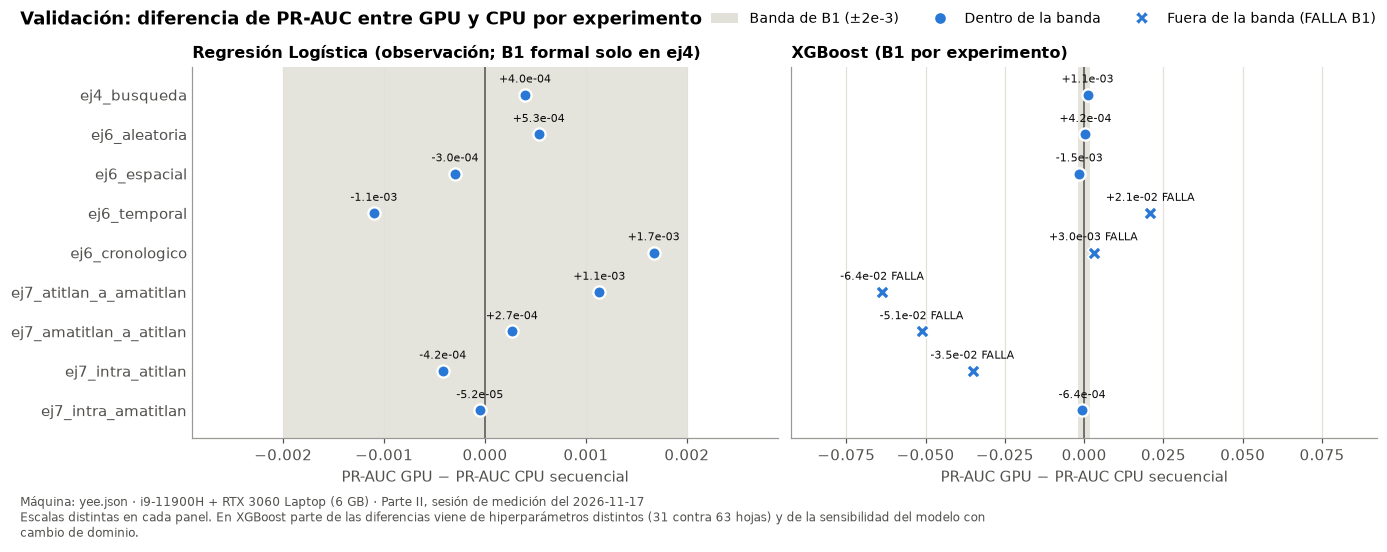

Guardado en resultados/graficos/: fig_07_validacion_dif_pr_auc.png


In [31]:
# 7.4 Gráfico: diferencia de PR-AUC (GPU − CPU secuencial) por experimento, con la banda del criterio B1
UMBRAL_B1 = 2e-3
deltas = {'regresion_logistica': metricas_rl.set_index('experimento').loc[EXPERIMENTOS, 'dif_pr_auc'].to_numpy(dtype=float),
          'xgboost': xv.set_index('experimento').loc[EXPERIMENTOS, 'dif_pr_auc'].to_numpy(dtype=float)}
titulos = {'regresion_logistica': 'Regresión Logística (observación; B1 formal solo en ej4)',
           'xgboost': 'XGBoost (B1 por experimento)'}
fig, ejes = plt.subplots(1, 2, figsize=(12.5, 4.4), layout='constrained')
y = np.arange(len(EXPERIMENTOS))[::-1]
for ax, modelo in zip(ejes, MODELOS):
    dd = deltas[modelo]
    pasa = np.abs(dd) <= UMBRAL_B1
    ax.axvspan(-UMBRAL_B1, UMBRAL_B1, color=GRIS_CLARO, alpha=0.9, linewidth=0)
    ax.axvline(0, color=TINTA_SECUNDARIA, linewidth=1)
    ax.scatter(dd[pasa], y[pasa], s=64, marker='o', color=COLOR['GPU'], edgecolor='white', linewidth=1.5, zorder=3)
    ax.scatter(dd[~pasa], y[~pasa], s=80, marker='X', color=COLOR['GPU'], edgecolor='white', linewidth=1, zorder=3)
    for xi_, yi, ok in zip(dd, y, pasa):
        ax.annotate(f'{xi_:+.1e}' + ('' if ok else ' FALLA'), (xi_, yi), xytext=(0, 8), textcoords='offset points',
                    ha='center', fontsize=7.5, color=TINTA)
    limite = max(np.abs(dd).max(), UMBRAL_B1) * 1.45
    ax.set_xlim(-limite, limite)
    ax.set_ylim(-0.7, len(EXPERIMENTOS) - 0.3)
    ax.set_yticks(y, EXPERIMENTOS)
    ax.set_title(titulos[modelo])
    ax.set_xlabel('PR-AUC GPU − PR-AUC CPU secuencial')
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
ejes[1].tick_params(axis='y', labelleft=False)
leyenda = [Patch(facecolor=GRIS_CLARO, label='Banda de B1 (±2e-3)'),
           Line2D([], [], marker='o', linestyle='', color=COLOR['GPU'], markeredgecolor='white', markersize=8, label='Dentro de la banda'),
           Line2D([], [], marker='X', linestyle='', color=COLOR['GPU'], markeredgecolor='white', markersize=9, label='Fuera de la banda (FALLA B1)')]
fig.legend(handles=leyenda, loc='outside upper right', ncol=3)
fig.suptitle('Validación: diferencia de PR-AUC entre GPU y CPU por experimento', x=0.01, ha='left', fontweight='bold', fontsize=11.5)
guardar_figura(fig, '07_validacion_dif_pr_auc', 'yee',
               'Escalas distintas en cada panel. En XGBoost parte de las diferencias viene de hiperparámetros distintos (31 contra 63 hojas) y de la sensibilidad del modelo con cambio de dominio.')

## 8. Control de las cifras de referencia

Cada fila compara una cifra calculada aquí con la cifra de referencia que se usa en el informe, redondeada con los mismos decimales. ✓ = coincide; ✗ = no coincide (revisar si es redondeo o un error en el texto). La tabla completa queda en `resultados/graficos/tabla_08_control_cifras.csv`.

In [32]:
# 8. Celda de control: cifras calculadas contra las cifras de referencia del informe
controles = []


def control(seccion, cifra, calculado, informe, dec, unidad=''):
    # Coincide si 'calculado' redondeado a 'dec' decimales da la cifra de referencia
    calculado = float(calculado)
    coincide = bool(np.isfinite(calculado)) and abs(calculado - informe) <= 0.5 * 10 ** (-dec) + 1e-9
    controles.append({'Tema': seccion, 'Cifra': cifra, 'Calculado': f'{calculado:.{dec}f}{unidad}',
                      'Referencia': f'{informe:.{dec}f}{unidad}', 'Coincide': '✓' if coincide else '✗',
                      'Calculado sin redondear': calculado})


# Parte I
for lago, esperados in [('Atitlán', (3.9, 11.9, 288, 6.7, 7.6)), ('Amatitlán', (6.9, 16.4, 331, 8.9, 9.7))]:
    for fase, esperado, dec in zip([K1_1N, K1_MULTI, K1_KERNEL, K1_SIMPLE, K1_STREAMS], esperados, [1, 1, 0, 1, 1]):
        control('Parte I · K1', f'K1 {lago}: speedup de {fase}', valor(datos_k1, lago, fase), esperado, dec, '×')
t_k1 = datos_k1.set_index(['lago', 'fase'])['promedio_s']
control('Parte I · K1', 'K1 Atitlán: copias como % del tiempo de GPU (simple)',
        100 * (t_k1[('Atitlán', K1_IDA)] + t_k1[('Atitlán', K1_VUELTA)]) / t_k1[('Atitlán', K1_SIMPLE)], 89, 0, ' %')
for lago, esperados in [('Atitlán', (2.0, 6.1, 6.2)), ('Amatitlán', (2.8, 5.6, 3.3))]:
    for fase, esperado in zip([K2_1N, K2_MULTI, K2_GPU], esperados):
        control('Parte I · K2', f'K2 aislado {lago}: speedup de {fase}', valor(datos_k2, lago, fase), esperado, 1, '×')
for lago, esperados in [('Atitlán', (11.6, 13.4, 8.7)), ('Amatitlán', (10.3, 9.1, 6.5))]:
    for fase, esperado in zip([P1_MULTI, P1_DATOS, P1_CAPAS], esperados):
        control('Parte I · K2', f'Parte I completa {lago}: speedup de {fase}', valor(datos_p1, lago, fase), esperado, 1, '×')
for fase, esperado, dec in [(K3_1N, 2.1, 1), (K3_MULTI, 10.8, 1), (K3_KERNEL, 39, 0), (K3_GPU, 36, 0)]:
    control('Parte I · K3', f'K3 Atitlán: speedup de {fase}', valor(datos_k3, 'Atitlán', fase), esperado, dec, '×')
for fase, esperado in [(K3_1N, 2.2), (K3_MULTI, 14.0), (K3_GPU, 8.8)]:
    control('Parte I · K3', f'K3 Amatitlán: speedup de {fase}', valor(datos_k3, 'Amatitlán', fase), esperado, 1, '×')
control('Parte I · K3', 'K3 Atitlán: GPU total vs CPU multinúcleo',
        valor(datos_k3, 'Atitlán', K3_MULTI, 'promedio_s') / valor(datos_k3, 'Atitlán', K3_GPU, 'promedio_s'), 3.4, 1, '×')
control('Parte I · K1', 'K1: píxeles distintos en máscaras (todas las versiones)', k1v.loc[k1v['tipo'] == 'mascara', 'pixeles_distintos'].sum(), 0, 0)
control('Parte I · K2', 'K2 GPU: dif. relativa máx. (×1e-6)', k2v.loc[k2v['version'] == 'GPU', 'dif_rel_max'].max() * 1e6, 1.03, 2)
control('Parte I · K3', 'K3: bins con conteo distinto (todas las versiones)', k3v['conteos_distintos'].sum(), 0, 0)
control('Parte I · lectura', 'Lectura: bandas distintas contra lab4', lecv['bandas_distintas'].sum(), 0, 0)

# Parte II: protocolo
pr = protocolo['regresion_logistica'].set_index('experimento')
px = protocolo['xgboost'].set_index('experimento')
for tabla_p, nombre, sec, esperados, dec_t, dec_s in [
        (pr, 'RL', 'Parte II · Regresión Logística', (29.52, 23.06, 3.14, 9.4, 7.4), 2, 1),
        (px, 'XGBoost', 'Parte II · XGBoost', (120.90, 49.61, 93.27, 1.30, 0.53), 2, 2)]:
    f = tabla_p.loc['Protocolo completo']
    control(sec, f'{nombre} protocolo: CPU secuencial', f['cpu_secuencial_s'], esperados[0], dec_t, ' s')
    control(sec, f'{nombre} protocolo: CPU multinúcleo', f['cpu_multinucleo_s'], esperados[1], dec_t, ' s')
    control(sec, f'{nombre} protocolo: GPU', f['gpu_s'], esperados[2], dec_t, ' s')
    control(sec, f'{nombre} protocolo: S vs secuencial', f['speedup_vs_secuencial'], esperados[3], dec_s, '×')
    control(sec, f'{nombre} protocolo: S vs multinúcleo', f['speedup_vs_multinucleo'], esperados[4], dec_s, '×')
ESPERADO_RL = {'ej4_busqueda': (8.1, 6.3), 'ej6_aleatoria': (13.0, 9.5), 'ej6_espacial': (13.4, 9.6),
               'ej6_temporal': (12.9, 9.6), 'ej6_cronologico': (9.7, 8.3), 'ej7_atitlan_a_amatitlan': (10.8, 8.6),
               'ej7_amatitlan_a_atitlan': (3.3, 2.3), 'ej7_intra_atitlan': (7.6, 6.3), 'ej7_intra_amatitlan': (2.7, 1.9)}
ESPERADO_XGB = {'ej4_busqueda': (1.55, 0.63), 'ej6_aleatoria': (1.65, 0.57), 'ej6_espacial': (1.56, 0.55),
                'ej6_temporal': (1.63, 0.59), 'ej6_cronologico': (1.57, 0.62), 'ej7_atitlan_a_amatitlan': (1.73, 0.67),
                'ej7_amatitlan_a_atitlan': (0.52, 0.32), 'ej7_intra_atitlan': (1.45, 0.60), 'ej7_intra_amatitlan': (0.44, 0.31)}
for tabla_p, nombre, sec, esperados, dec in [(pr, 'RL', 'Parte II · Regresión Logística', ESPERADO_RL, 1), (px, 'XGBoost', 'Parte II · XGBoost', ESPERADO_XGB, 2)]:
    for exp, (a, b) in esperados.items():
        control(sec, f'{nombre} {exp}: S vs secuencial', tabla_p.loc[exp, 'speedup_vs_secuencial'], a, dec, '×')
        control(sec, f'{nombre} {exp}: S vs multinúcleo', tabla_p.loc[exp, 'speedup_vs_multinucleo'], b, dec, '×')

# Unidades representativas
for modelo, nombre, sec, esperados in [
        ('regresion_logistica', 'RL', 'Parte II · Regresión Logística', {'busqueda': ((8.0, 1), (6.3, 1)), 'entrenamiento': ((15.8, 1), (15.3, 1)), 'prediccion': ((11.9, 1), (11.8, 1))}),
        ('xgboost', 'XGBoost', 'Parte II · XGBoost', {'busqueda': ((1.60, 2), (0.64, 2)), 'entrenamiento': ((1.37, 2), (0.50, 2)), 'prediccion': ((57, 0), (9.6, 1))})]:
    rep = representativos[modelo]
    for unidad, ((a, da), (b, db)) in esperados.items():
        control(sec, f'{nombre} representativo {unidad}: S vs secuencial', rep.loc[unidad, 'speedup_vs_secuencial'], a, da, '×')
        control(sec, f'{nombre} representativo {unidad}: S vs multinúcleo', rep.loc[unidad, 'speedup_vs_multinucleo'], b, db, '×')

# Con y sin copias
fx = datos_fases.set_index('clave')
ESPERADO_FASES = [
    ('Parte II · con y sin copias', 'regresion_logistica:protocolo', 'gpu_sin_copias_s', 2.91, 2, ' s', 'RL protocolo: GPU sin copias (cota)'),
    ('Parte II · con y sin copias', 'regresion_logistica:protocolo', 'S_sin_vs_secuencial', 10.2, 1, '×', 'RL protocolo: S sin copias vs secuencial (cota: a lo sumo)'),
    ('Parte II · con y sin copias', 'regresion_logistica:protocolo', 'S_sin_vs_multinucleo', 7.9, 1, '×', 'RL protocolo: S sin copias vs multinúcleo (cota: a lo sumo)'),
    ('Parte II · con y sin copias', 'regresion_logistica:entrenamiento', 'gpu_sin_copias_s', 0.0319, 4, ' s', 'RL entrenamiento: GPU sin copias'),
    ('Parte II · con y sin copias', 'regresion_logistica:entrenamiento', 'S_sin_vs_secuencial', 16.8, 1, '×', 'RL entrenamiento: S sin copias vs secuencial'),
    ('Parte II · con y sin copias', 'regresion_logistica:entrenamiento', 'S_sin_vs_multinucleo', 16.3, 1, '×', 'RL entrenamiento: S sin copias vs multinúcleo'),
    ('Parte II · con y sin copias', 'regresion_logistica:prediccion', 'gpu_sin_copias_s', 0.00022, 5, ' s', 'RL predicción: GPU sin copias'),
    ('Parte II · con y sin copias', 'regresion_logistica:prediccion', 'S_sin_vs_secuencial', 68, 0, '×', 'RL predicción: S sin copias vs secuencial'),
    ('Parte II · con y sin copias', 'regresion_logistica:prediccion', 'S_sin_vs_multinucleo', 67, 0, '×', 'RL predicción: S sin copias vs multinúcleo'),
    ('Parte II · con y sin copias', 'xgboost:protocolo', 'gpu_sin_copias_s', 92.7, 1, ' s', 'XGBoost protocolo: GPU sin copias (cota)'),
    ('Parte II · con y sin copias', 'xgboost:protocolo', 'S_sin_vs_secuencial', 1.30, 2, '×', 'XGBoost protocolo: S sin copias vs secuencial'),
    ('Parte II · con y sin copias', 'xgboost:protocolo', 'S_sin_vs_multinucleo', 0.53, 2, '×', 'XGBoost protocolo: S sin copias vs multinúcleo'),
    ('Parte II · con y sin copias', 'xgboost:entrenamiento', 'gpu_sin_copias_s', 1.286, 3, ' s', 'XGBoost entrenamiento final: GPU sin copias'),
    ('Parte II · con y sin copias', 'xgboost:entrenamiento', 'S_sin_vs_secuencial', 1.38, 2, '×', 'XGBoost entrenamiento final: S sin copias vs secuencial'),
    ('Parte II · con y sin copias', 'xgboost:entrenamiento', 'S_sin_vs_multinucleo', 0.50, 2, '×', 'XGBoost entrenamiento final: S sin copias vs multinúcleo'),
    ('Parte II · con y sin copias', 'xgboost:prediccion', 'gpu_sin_copias_s', 0.00187, 5, ' s', 'XGBoost predicción: GPU sin copias'),
    ('Parte II · con y sin copias', 'xgboost:prediccion', 'S_sin_vs_secuencial', 86, 0, '×', 'XGBoost predicción: S sin copias vs secuencial'),
    ('Parte II · con y sin copias', 'xgboost:prediccion', 'S_sin_vs_multinucleo', 14, 0, '×', 'XGBoost predicción: S sin copias vs multinúcleo'),
    ('Parte II · XGBoost, mismos hiperparámetros', 'xgboost:ajuste_281255', 'S_con_vs_secuencial', 2.85, 2, '×', 'XGBoost ajuste controlado: S vs secuencial'),
    ('Parte II · XGBoost, mismos hiperparámetros', 'xgboost:ajuste_281255', 'S_con_vs_multinucleo', 1.19, 2, '×', 'XGBoost ajuste controlado: S vs multinúcleo'),
    ('Parte II · XGBoost, mismos hiperparámetros', 'xgboost:ajuste_281255', 'S_sin_vs_secuencial', 2.87, 2, '×', 'XGBoost ajuste controlado: S sin copias vs secuencial'),
    ('Parte II · XGBoost, mismos hiperparámetros', 'xgboost:ajuste_281255', 'S_sin_vs_multinucleo', 1.20, 2, '×', 'XGBoost ajuste controlado: S sin copias vs multinúcleo'),
    ('Parte II · con y sin copias', 'xgboost:ajuste_281255', 'gpu_sin_copias_s', 0.628, 3, ' s', 'XGBoost ajuste controlado: GPU sin copias'),
    ('Parte II · XGBoost, mismos hiperparámetros', 'xgboost:prediccion_281255', 'S_con_vs_secuencial', 67, 0, '×', 'XGBoost predicción controlada: S vs secuencial (≈)'),
    ('Parte II · XGBoost, mismos hiperparámetros', 'xgboost:prediccion_281255', 'S_con_vs_multinucleo', 15, 0, '×', 'XGBoost predicción controlada: S vs multinúcleo (≈)'),
    ('Parte II · XGBoost, escalabilidad', 'xgboost:ajuste_3750000', 'S_con_vs_secuencial', 16.7, 1, '×', 'XGBoost 3.75 M: S vs secuencial'),
    ('Parte II · XGBoost, escalabilidad', 'xgboost:ajuste_3750000', 'S_con_vs_multinucleo', 7.0, 1, '×', 'XGBoost 3.75 M: S vs multinúcleo'),
    ('Parte II · XGBoost, escalabilidad', 'xgboost:ajuste_3750000', 'S_sin_vs_secuencial', 17.1, 1, '×', 'XGBoost 3.75 M: S sin copias vs secuencial'),
    ('Parte II · XGBoost, escalabilidad', 'xgboost:ajuste_3750000', 'S_sin_vs_multinucleo', 7.2, 1, '×', 'XGBoost 3.75 M: S sin copias vs multinúcleo'),
    ('Parte II · con y sin copias', 'xgboost:ajuste_3750000', 'gpu_sin_copias_s', 1.361, 3, ' s', 'XGBoost 3.75 M: GPU sin copias'),
    ('Parte II · XGBoost, escalabilidad', 'xgboost:prediccion_3750000', 'S_con_vs_secuencial', 56, 0, '×', 'XGBoost predicción 1.6 M: S vs secuencial'),
    ('Parte II · XGBoost, escalabilidad', 'xgboost:prediccion_3750000', 'S_con_vs_multinucleo', 11.7, 1, '×', 'XGBoost predicción 1.6 M: S vs multinúcleo'),
    ('Parte II · con y sin copias', 'xgboost:prediccion_3750000', 'S_sin_vs_secuencial', 127, 0, '×', 'XGBoost predicción 1.6 M: S sin copias vs secuencial'),
    ('Parte II · con y sin copias', 'xgboost:prediccion_3750000', 'S_sin_vs_multinucleo', 27, 0, '×', 'XGBoost predicción 1.6 M: S sin copias vs multinúcleo'),
    ('Parte II · con y sin copias', 'xgboost:prediccion_3750000', 'gpu_sin_copias_s', 0.0140, 4, ' s', 'XGBoost predicción 1.6 M: GPU sin copias'),
]
for sec, clave, columna, esperado, dec, unidad, cifra in ESPERADO_FASES:
    control(sec, cifra, fx.loc[clave, columna], esperado, dec, unidad)

# Escalabilidad y costo fijo
crec = datos_escala.set_index(['fase', 'version'])['crecimiento']
for variante, esperado in [('GPU', 2.2), ('CPU secuencial', 12.9), ('CPU multinúcleo', 13.0)]:
    control('Parte II · XGBoost, escalabilidad', f'Crecimiento del ajuste {variante} (281 mil → 3.75 M)', crec[('Ruta real ajustar() (la del protocolo)', variante)], esperado, 1, '×')
control('Parte II · XGBoost, escalabilidad', 'Costo fijo estimado por ajuste en GPU', costo_fijo, 0.57, 2, ' s')
control('Parte II · XGBoost, escalabilidad', 'Costo por fila en GPU (µs)', pendiente * 1e6, 0.22, 2)
control('Parte II · XGBoost, escalabilidad', 'Costo fijo como % del ajuste de 281 mil filas', 100 * costo_fijo / g1, 90, 0, ' %')

# Copias, en ms
for clave, esperado in [('xy', 2.01), ('x_prueba', 0.83), ('prob_rl', 0.21), ('prob_xgb', 0.11)]:
    control('Parte II · con y sin copias', f'Copia {clave} (ms)', COPIA[clave] * 1000, esperado, 2)

# nvidia-smi
ESPERADO_SMI = {
    'regresion_logistica': [('filas_csv', 597, 0), ('vueltas', 15, 0), ('util_max', 65, 0), ('util_prom', 18.7, 1), ('umem_max', 21, 0), ('umem_prom', 5.6, 1),
                            ('mem_max', 243, 0), ('mem_prom', 236.7, 1), ('pot_max', 60, 0), ('pot_prom', 43.9, 1), ('temp_max', 67, 0), ('temp_prom', 60.2, 1)],
    'xgboost': [('filas_csv', 476, 0), ('vuelta_max_s', 96.3, 1), ('calentamiento_s', 3.4, 1), ('util_max', 48, 0), ('util_prom', 38.2, 1), ('umem_max', 8, 0), ('umem_prom', 2.4, 1),
                ('mem_max', 337, 0), ('mem_prom', 280.5, 1), ('pot_max', 53.2, 1), ('pot_prom', 45.7, 1), ('temp_max', 65, 0), ('temp_prom', 60.2, 1)],
}
for modelo, lista in ESPERADO_SMI.items():
    for clave, esperado, dec in lista:
        control('Parte II · nvidia-smi', f'nvidia-smi {MODELOS[modelo]}: {clave}', resumen_smi[modelo][clave], esperado, dec)

# Validación
control('Parte II · validación RL', 'RL: ajustes de ej4 que pasan A/B1/B2/B3', (lv['pasa'].astype(str) == 'True').sum(), 11, 0)
control('Parte II · validación RL', 'RL: máx |Δ PR-AUC| en el protocolo (×1e-3)', metricas_rl['dif_pr_auc'].abs().max() * 1e3, 1.7, 1)
control('Parte II · validación RL', 'RL: máx |Δ ROC-AUC| en el protocolo (×1e-4)', metricas_rl['dif_roc_auc'].abs().max() * 1e4, 2.4, 1)
control('Parte II · validación RL', 'RL: máx |Δ F2| en el protocolo (×1e-3)', metricas_rl['dif_f2'].abs().max() * 1e3, 9.4, 1)
control('Parte II · validación XGBoost', 'XGBoost: experimentos que fallan B1', (xv['B1_ok'].astype(str) == 'False').sum(), 5, 0)
control('Parte II · validación XGBoost', 'XGBoost mismos hiperparámetros: máx |Δ PR-AUC| (×1e-4)', xi['dif_pr_auc'].abs().max() * 1e4, 6.3, 1)
control('Parte II · validación XGBoost', 'XGBoost mismos hiperparámetros: máx |Δ ROC-AUC| (×1e-4)', xi['dif_roc_auc'].abs().max() * 1e4, 5.9, 1)
control('Parte II · validación XGBoost', 'XGBoost prueba extendida: experimentos comparables al ruido', xe['lectura'].str.startswith('comparable').sum(), 5, 0)
control('Parte II · validación XGBoost', 'XGBoost prueba extendida: razón GPU / ruido máxima', xe['razon_gpu_sobre_ruido'].max(), 1.63, 2)

# Preparación de datos
construccion = datos_prep.set_index('fase').loc['Construccion del dataset (22 escenas)']
control('Parte II · preparación de datos', 'Construcción del dataset: CPU secuencial', construccion['cpu_secuencial_s'], 13.044, 3, ' s')
control('Parte II · preparación de datos', 'Construcción del dataset: CPU multinúcleo', construccion['cpu_multinucleo_s'], 5.881, 3, ' s')
control('Parte II · preparación de datos', 'Construcción del dataset: speedup', construccion['speedup'], 2.2, 1, '×')

tabla_control = pd.DataFrame(controles)
no_coinciden = tabla_control[tabla_control['Coincide'] == '✗']
print(f'{len(tabla_control)} cifras comparadas; {len(no_coinciden)} no coinciden con las cifras de referencia.')
if len(no_coinciden):
    display(Markdown('**Cifras que no coinciden:**'))
    display(no_coinciden.drop(columns=['Calculado sin redondear']))
else:
    display(Markdown('**Todas las cifras coinciden.**'))
guardar_tabla(tabla_control.drop(columns=['Calculado sin redondear']), '08_control_cifras',
              datos=tabla_control, mostrar=False)

175 cifras comparadas; 15 no coinciden con las cifras de referencia.


**Cifras que no coinciden:**

,Tema,Cifra,Calculado,Referencia,Coincide
2,Parte I · K1,K1 Atitlán: speedup de GPU: kernel (sin copias),289×,288×,✗
7,Parte I · K1,K1 Amatitlán: speedup de GPU: kernel (sin copias),330×,331×,✗
24,Parte I · K3,K3 Atitlán: speedup de CPU multinúcleo (Numba),10.6×,10.8×,✗
25,Parte I · K3,K3 Atitlán: speedup de GPU: kernel (sin copia),40×,39×,✗
26,Parte I · K3,K3 Atitlán: speedup de GPU total (con la copia),35×,36×,✗
28,Parte I · K3,K3 Amatitlán: speedup de CPU multinúcleo (Numba),15.3×,14.0×,✗
29,Parte I · K3,K3 Amatitlán: speedup de GPU total (con la copia),9.3×,8.8×,✗
30,Parte I · K3,K3 Atitlán: GPU total vs CPU multinúcleo,3.3×,3.4×,✗
49,Parte II · Regresión Logística,RL ej6_espacial: S vs secuencial,13.5×,13.4×,✗
50,Parte II · Regresión Logística,RL ej6_espacial: S vs multinúcleo,9.7×,9.6×,✗


Guardado en resultados/graficos/: tabla_08_control_cifras.csv, tabla_08_control_cifras_datos.csv
